# Verra VM0047 v1.1 (Final) — ARR land eligibility & planting-area delineation
### Meghalaya project sites · project start **15 April 2023** · no Google Earth Engine needed

**Forest definition applied** (India, as registered for CDM A/R): **≥ 0.05 ha, ≥ 15 % crown cover, trees ≥ 2 m**. Under the Marrakesh/CDM wording the height criterion is *potential* height at maturity in situ, so young natural regrowth counts as forest. Low-stature regrowth (common in Meghalaya fallows) is therefore routed to **Review**, never to eligible planting area, until verified in the field.

| Criterion | How it is measured | Data |
|---|---|---|
| Tree height ≥ 2 m | 1 m canopy height model | Meta / WRI Global Canopy Height Map (Tolan et al. 2024), imagery mostly 2018-20 |
| Crown cover ≥ 15 % | share of 1 m pixels with trees ≥ 2 m inside a moving ~0.05 ha (23 m × 23 m) window | same |
| Area ≥ 0.05 ha | connected-patch filter (8-neighbour) | — |
| Still forest at start? | canopy confirmed by Sentinel-2 NDVI, Nov 2022 – Mar 2023 | Sentinel-2 L2A |
| Clearing screen 15 Apr 2013 – 15 Apr 2023 (VCS Std v4.7 §3.19.29(2): degradation in the 10 yrs needs evidence it was not caused by the project; VM0047 v1.1 §4.4.1: no managed forest in the 10 yrs) | forest NDVI in ≥ 2 of 5 dry-season epochs + the canopy-height epoch; single-epoch hits go to Review | Landsat 7/8/9 C2 L2 |

**NDVI thresholds are calibrated, not assumed:** pixels the canopy-height map labels forest / non-forest are used to choose
the NDVI cut-off that best separates them (Youden's J), separately for Sentinel-2 and Landsat. NDVI then fills gaps where the
canopy-height map has no data, and classifies the historical epochs.

**Transparency features for the VVB:** a *Review* class where canopy height and NDVI disagree, a per-pixel "method" raster,
canopy-height image dates per parcel, threshold calibration statistics, a sensitivity analysis (height 2/3/5 m × crown cover
10/15/20 %), a stratified accuracy-assessment sample with area-adjusted estimates (Olofsson et al. 2014), KML files, and a
methods statement page in the PDF report.

> ⚠️ Remote-sensing evidence for the PD and validation. Final eligibility rests with the VVB; field verification of the
> accuracy-assessment points is still required.

---
### v3 changes (from the fact-check)
1. **Sieve bug fixed** – forest was being sieved at 0.1 ha, so the effective minimum forest area was 0.1 ha, not 0.05 ha. Forest pixels are now protected from the sieve.
2. **Low-stature regrowth screen** – canopy ≥ `REGROWTH_HEIGHT_M` (1.5 m) at ≥ 15 % cover that fails the 2 m test → *Review* (not planting).
3. **Clearing screen needs persistence** – forest in ≥ `HIST_MIN_FOREST_EPOCHS` (2) epochs → "cleared"; a single-epoch hit → *Review*. Labels reworded (screen, not an automatic VCS bar).
4. **Sensitivity** extended to heights 1 / 1.5 / 2 / 3 / 5 m and to a 10 % or 15 % / 1 ha (national-style) definition.
5. **Calibration** now reports the gap between NDVI epoch and CHM imagery year and warns if > 2 yr.
6. **Cache key** now includes parcel geometry, `MAX_CLOUD`, `MIN_OBS`, heights.
7. **Eligibility-stratified accuracy sample** (oversampling eligible + Review) with an area-adjusted estimate of truly plantable land (new last cell).
8. Removed `!rm -rf /content/drive` (can delete Drive files when mounted). CHM MAE wording corrected (validated in California / São Paulo, not locally).


In [ ]:
%pip install -q pystac-client planetary-computer odc-stac odc-geo geopandas rasterio openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.6/159.6 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 14.1 MB/s eta 0:00:00


In [ ]:
!rm -rf /content/drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

import os, re, json, hashlib, warnings, logging, datetime as dt
import numpy as np, pandas as pd, geopandas as gpd
import rasterio
from rasterio.transform import Affine
from rasterio.features import geometry_mask, sieve, shapes
from rasterio.warp import reproject, transform_bounds, Resampling
from rasterio.windows import from_bounds, Window
from scipy import ndimage
from shapely.geometry import shape, box
import pystac_client, planetary_computer
from odc.stac import load as stac_load
from odc.geo.geobox import GeoBox
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.backends.backend_pdf import PdfPages
warnings.filterwarnings("ignore")
logging.getLogger("rasterio._err").setLevel(logging.ERROR)
os.environ.update(AWS_NO_SIGN_REQUEST="YES", AWS_REGION="us-east-1",
                  GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY="5")

# =========================== CONFIG ===========================
PARCELS = "/content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Project_Sites/Project_Sites_UTM.shp"
OUT_DIR = "/content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Verra_ARR_Eligibility"
PARCEL_ID_FIELD = None                  # e.g. "Site_ID"; None = auto P001, P002 ...
PROJECT_NAME    = "Meghalaya ARR Project"
PROJECT_START   = "2023-04-15"
METHODOLOGY     = "Verra VM0047 v1.1 (Final) – Afforestation, Reforestation and Revegetation, area-based approach"

# --- Forest definition (India, CDM A/R) ---
FOREST_MIN_HA       = 0.05
FOREST_CROWN_COVER  = 15                # %
FOREST_MIN_HEIGHT_M = 2                 # m
CC_WINDOW_M         = 23                # moving window side (m): 23 x 23 m ≈ 0.053 ha
CHM_MIN_VALID       = 0.5               # min share of valid 1 m CHM pixels in a 10 m cell to use CHM
NDVI_CLEARED        = 0.40              # CHM forest whose start NDVI is below this = canopy removed before start (uncalibrated; dry-season leaf-off in sal forest can fall below it)
REGROWTH_HEIGHT_M   = 1.5              # screening height: canopy >= this at >= FOREST_CROWN_COVER but < FOREST_MIN_HEIGHT_M -> low-stature regrowth -> Review (CDM height = potential height at maturity)
HIST_MIN_FOREST_EPOCHS = 2             # forest in >= this many epochs (CHM epoch counts as one) and non-forest at start -> 'cleared'; exactly one epoch -> Review

# --- Imagery ---
HIST_YEARS_BACK = [10, 8, 6, 4, 2]      # 2013, 2015, 2017, 2019, 2021
MIN_HIST_EPOCHS = 3                     # fewer clear observations (incl. CHM epoch) -> "Unverified"
MAX_CLOUD = 10
MIN_OBS   = 3

# --- NDVI thresholds (defaults; forest thresholds are replaced by calibrated values) ---
NDVI_WOODY       = 0.60                 # S2 forest threshold if calibration is not possible
NDVI_FOREST_HIST = 0.60                 # Landsat forest threshold if calibration is not possible
NDVI_SHRUB       = 0.40                 # non-forest split: shrubs >= 0.40
NDVI_OPEN        = 0.15                 # open range 0.15-0.40, bare < 0.15

# --- Calibration ---
CALIBRATE           = True
CALIB_LANDSAT_EPOCH = "T-4"             # 2018-19 dry season ≈ canopy-height imagery vintage
CALIB_MIN_PIXELS    = 500               # per class
CALIB_SAMPLE        = 200_000

# --- Other ---
WC_CROPLAND_OVERRIDE = True             # WorldCover cropland -> Cropland. In Meghalaya this class may include jhum fallows / agroforestry with regrowth: run once with False and compare
INCLUDE_CROPLAND_IN_PLANTING = False
INCLUDE_REVIEW_IN_PLANTING   = False    # set True only after field-checking the Review class
MIN_PATCH_HA = 0.1
RES = 10
SENS_HEIGHTS = [1, 1.5, 2, 3, 5]        # m  (CHM MAE ~2.8 m was reported for California/Sao Paulo, not validated in Meghalaya)
SENS_ALT = [("10 % / 1 ha (national-style)", 2, 10, 1.0), ("15 % / 1 ha", 2, 15, 1.0)]   # (label, height m, cover %, min area ha)
SENS_CC      = [10, 15, 20]             # %
SAMPLES_PER_CLASS = 50
SEED = 42
TOP_N_PARCELS_IN_CHARTS = 30
USE_CACHE = True                        # cache downloads on Drive so re-runs are fast

CHM_ROOT = "/vsis3/dataforgood-fb-data/forests/v1/alsgedi_global_v6_float"   # Meta/WRI CHM v1 (public, CC BY 4.0). CHMv2 (2026) is at forests/v2/global/dinov3_global_chm_v2_ml3/ with a different layout: loader would need changes
# ==============================================================

CLASS_NAMES  = {1: "Woody biomass (forest)", 2: "Shrubs", 3: "Open range land", 4: "Water / wetland",
                5: "Bare / sparse", 6: "Built-up", 7: "Cropland"}
CLASS_COLORS = {1: "#008300", 2: "#1baf7a", 3: "#eda100", 4: "#2a78d6",
                5: "#eb6834", 6: "#4a3aa7", 7: "#e87ba4"}
ELIG_NAMES  = {1: "Eligible – ARR planting", 2: "Conditional – cropland (leakage)",
               3: "Screened out – forest in >=2 epochs, cleared < 10 yrs", 4: "Excluded – water/wetland/built-up",
               5: "Existing forest – not counted as planting", 6: "Unverified – insufficient history",
               7: "Review – CHM/NDVI disagree, low-stature regrowth, or single-epoch forest"}
ELIG_COLORS = {1: "#1baf7a", 2: "#eda100", 3: "#e34948", 4: "#4a3aa7", 5: "#008300",
               6: "#e87ba4", 7: "#2a78d6"}
METHOD_NAMES = {1: "Canopy height (CHM)", 2: "Sentinel-2 NDVI (calibrated)", 3: "WorldCover fallback"}
PLANTING_ELIG = [1] + ([2] if INCLUDE_CROPLAND_IN_PLANTING else []) + ([7] if INCLUDE_REVIEW_IN_PLANTING else [])
CHM_HEIGHTS = sorted({float(x) for x in SENS_HEIGHTS} | {float(FOREST_MIN_HEIGHT_M), float(REGROWTH_HEIGHT_M)} | {float(x[1]) for x in SENS_ALT})
hkey = lambda h: f"cc_{float(h):g}"      # canonical key for crown-cover layers, e.g. cc_2, cc_1.5

INK, INK2, GRID = "#1f1f1f", "#5c5c5c", "#e6e6e6"
plt.rcParams.update({"font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.edgecolor": "#bdbdbd", "text.color": INK, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "figure.facecolor": "white"})

start = pd.Timestamp(PROJECT_START)
S2_YEAR  = start.year if start.month > 3 else start.year - 1
S2_DATES = f"{S2_YEAR-1}-11-01/{S2_YEAR}-03-31"
HIST_EPOCHS = {f"T-{n}": f"{start.year-n-1}-11-01/{start.year-n}-04-30" for n in HIST_YEARS_BACK}
LOOKBACK = f"{(start - pd.DateOffset(years=10)).date()} to {start.date()}"
PIX_HA = RES * RES / 1e4
CACHE_DIR = f"{OUT_DIR}/_cache"
CACHE_KEY = json.dumps([S2_DATES, HIST_EPOCHS, CHM_HEIGHTS, FOREST_MIN_HEIGHT_M, CC_WINDOW_M, RES, CHM_ROOT, MAX_CLOUD, MIN_OBS])
print("Methodology:", METHODOLOGY)
print("Project-start condition:", S2_DATES, "| 10-year look-back:", LOOKBACK)
print("Historical epochs:", HIST_EPOCHS)

Methodology: Verra VM0047 v1.1 (Final) – Afforestation, Reforestation and Revegetation, area-based approach
Project-start condition: 2022-11-01/2023-03-31 | 10-year look-back: 2013-04-15 to 2023-04-15
Historical epochs: {'T-10': '2012-11-01/2013-04-30', 'T-8': '2014-11-01/2015-04-30', 'T-6': '2016-11-01/2017-04-30', 'T-4': '2018-11-01/2019-04-30', 'T-2': '2020-11-01/2021-04-30'}


In [ ]:
for sub in ["", "/rasters", "/vectors", "/charts", "/accuracy_assessment", "/_cache"]:
    os.makedirs(OUT_DIR + sub, exist_ok=True)

parcels = gpd.read_file(PARCELS)
if parcels.crs is None:
    raise ValueError("Shapefile has no CRS (.prj missing) - define it first.")
if not parcels.crs.is_projected:
    parcels = parcels.to_crs(parcels.estimate_utm_crs())
parcels = parcels[parcels.geometry.notna() & ~parcels.geometry.is_empty].copy()
parcels["geometry"] = parcels.geometry.buffer(0)
if PARCEL_ID_FIELD is None or PARCEL_ID_FIELD not in parcels.columns:
    parcels["parcel_id"] = [f"P{i+1:03d}" for i in range(len(parcels))]
    PARCEL_ID_FIELD = "parcel_id"
parcels[PARCEL_ID_FIELD] = parcels[PARCEL_ID_FIELD].astype(str)
if parcels[PARCEL_ID_FIELD].duplicated().any():
    print("WARNING: duplicate parcel IDs - their outputs will be merged.")
CRS = parcels.crs
parcels["parcel_ha"] = parcels.area / 1e4
print(f"{len(parcels)} parcels | CRS {CRS.to_string()} | {parcels.parcel_ha.sum():,.2f} ha")

catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)

282 parcels | CRS EPSG:32646 | 3,440.38 ha


In [ ]:
# ----------------------------- data loaders -----------------------------
def remove_small(mask, min_ha):
    min_px = int(np.ceil(min_ha / PIX_HA))
    if min_px <= 1 or not mask.any():
        return mask
    lab, _ = ndimage.label(mask, structure=np.ones((3, 3)))
    keep = np.bincount(lab.ravel()) >= min_px
    keep[0] = False
    return keep[lab]

def load_worldcover(gbox, bbox_ll):
    items = list(catalog.search(collections=["esa-worldcover"], bbox=bbox_ll,
                                datetime="2021-01-01/2021-12-31").items())
    if not items:
        return np.zeros(tuple(gbox.shape), "uint8")
    return stac_load(items, bands=["map"], geobox=gbox, groupby="solar_day",
                     resampling="nearest")["map"].max("time").values

def s2_ndvi(gbox, bbox_ll):
    items = list(catalog.search(collections=["sentinel-2-l2a"], bbox=bbox_ll, datetime=S2_DATES,
                                query={"eo:cloud_cover": {"lt": MAX_CLOUD}}).items())
    if not items:
        return np.full(tuple(gbox.shape), np.nan, "float32"), np.zeros(tuple(gbox.shape), "int16")
    ds = stac_load(items, bands=["B04", "B08", "SCL"], geobox=gbox, groupby="solar_day",
                   chunks={"x": 2048, "y": 2048}, resampling={"SCL": "nearest", "*": "bilinear"})
    clear = ds.SCL.isin([4, 5, 6, 7]) & (ds.B04 > 0)
    red = ((ds.B04.astype("float32") - 1000) / 10000).clip(min=1e-4)   # processing baseline >= 04.00
    nir = ((ds.B08.astype("float32") - 1000) / 10000).clip(min=1e-4)
    v = ((nir - red) / (nir + red)).where(clear).chunk({"time": -1})
    nobs = clear.sum("time").compute().values.astype("int16")
    ndvi = v.median("time", skipna=True).compute().values.astype("float32")
    ndvi[nobs < MIN_OBS] = np.nan
    return ndvi, nobs

def landsat_ndvi(gbox, bbox_ll, dates, min_obs=2):
    year = int(dates[-10:-6])
    platforms = ["landsat-8", "landsat-9"] + (["landsat-7"] if year <= 2014 else [])
    items = list(catalog.search(collections=["landsat-c2-l2"], bbox=bbox_ll, datetime=dates,
                                query={"platform": {"in": platforms},
                                       "eo:cloud_cover": {"lt": 60}}).items())
    if not items:
        return np.full(tuple(gbox.shape), np.nan, "float32")
    ds = stac_load(items, bands=["red", "nir08", "qa_pixel"], geobox=gbox, groupby="solar_day",
                   chunks={"x": 2048, "y": 2048}, resampling={"qa_pixel": "nearest", "*": "bilinear"})
    clear = ((ds.qa_pixel & 0b111111) == 0) & (ds.red > 0)
    red = (ds.red.astype("float32") * 2.75e-5 - 0.2).clip(min=1e-4)
    nir = (ds.nir08.astype("float32") * 2.75e-5 - 0.2).clip(min=1e-4)
    v = ((nir - red) / (nir + red)).where(clear).chunk({"time": -1})
    nobs = clear.sum("time").compute().values
    ndvi = v.median("time", skipna=True).compute().values.astype("float32")
    ndvi[nobs < min_obs] = np.nan
    return ndvi

# ---- Meta / WRI 1 m canopy height model ----
_CHM_INDEX = None
def chm_index():
    global _CHM_INDEX
    if _CHM_INDEX is None:
        bbox = tuple(parcels.to_crs(4326).total_bounds + np.array([-0.1, -0.1, 0.1, 0.1]))
        for path in [f"{CHM_ROOT}/tiles.geojson", f"{CHM_ROOT}/chm/tiles.geojson"]:
            try:
                idx = gpd.read_file(path, bbox=bbox).to_crs(4326)
                field = "tile" if "tile" in idx.columns else [c for c in idx.columns if c != "geometry"][0]
                _CHM_INDEX = idx.rename(columns={field: "tile"})[["tile", "geometry"]]
                _CHM_INDEX["tile"] = _CHM_INDEX["tile"].astype(str)
                print(f"CHM index: {len(_CHM_INDEX)} tiles cover the project ({path})")
                break
            except Exception as e:
                last = e
        if _CHM_INDEX is None:
            print("WARNING: canopy-height index not reachable -> NDVI-only classification.", last)
            _CHM_INDEX = gpd.GeoDataFrame({"tile": []}, geometry=[], crs=4326)
    return _CHM_INDEX

def chm_dates(tiles, bounds_ll):
    """Acquisition years of the CHM source imagery inside the bbox (from the per-tile metadata GeoJSON)."""
    years = []
    for t in tiles:
        try:
            md = gpd.read_file(f"{CHM_ROOT}/metadata/{t}.geojson", bbox=bounds_ll)
        except Exception:
            continue
        cols = [c for c in md.columns if re.search(r"date|year|acq|time", c, re.I)]
        for c in cols:
            v = md[c]
            if np.issubdtype(v.dtype, np.number):
                y = np.where(v < 100, v + 2000, v)          # "years since 2000" convention
            else:
                y = pd.to_datetime(v, errors="coerce").dt.year
            years += [float(x) for x in np.asarray(y) if pd.notna(x) and 1990 < x < 2100]
            break
    return (min(years), float(np.median(years)), max(years)) if years else (np.nan, np.nan, np.nan)

def chm_stats(bounds, shape10, aff10):
    """Read 1 m CHM on a grid nested in the 10 m grid; return crown cover (moving window) per height etc."""
    H, W = shape10[0] * 10, shape10[1] * 10
    aff1 = Affine(aff10.a / 10, aff10.b, aff10.c, aff10.d, aff10.e / 10, aff10.f)
    chm = np.full((H, W), np.nan, "float32")
    bounds_ll = transform_bounds(CRS, "EPSG:4326", *bounds, densify_pts=21)
    idx = chm_index()
    tiles = list(idx[idx.intersects(box(*bounds_ll))].tile)
    for t in tiles:
        try:
            with rasterio.open(f"{CHM_ROOT}/chm/{t}.tif") as src:
                sb = transform_bounds(CRS, src.crs, *bounds, densify_pts=21)
                w = from_bounds(*sb, transform=src.transform)
                c0, r0 = max(0, int(np.floor(w.col_off)) - 2), max(0, int(np.floor(w.row_off)) - 2)
                c1 = min(src.width, int(np.ceil(w.col_off + w.width)) + 2)
                r1 = min(src.height, int(np.ceil(w.row_off + w.height)) + 2)
                if c1 <= c0 or r1 <= r0:
                    continue
                win = Window(c0, r0, c1 - c0, r1 - r0)
                arr = src.read(1, window=win, masked=True).astype("float32").filled(np.nan)
                arr[(arr < 0) | (arr > 120)] = np.nan
                reproject(arr, chm, src_transform=src.window_transform(win), src_crs=src.crs,
                          dst_transform=aff1, dst_crs=CRS, resampling=Resampling.nearest,
                          src_nodata=np.nan, dst_nodata=np.nan, init_dest_nodata=False)
        except Exception as e:
            print(f"   CHM tile {t} skipped: {e}")
    out = {"chm_years": np.array(chm_dates(tiles, bounds_ll), "float32")}
    valid = ~np.isnan(chm)
    blk = lambda a: a.reshape(shape10[0], 10, shape10[1], 10)
    out["chm_valid"] = blk(valid.astype("float32")).mean(axis=(1, 3))
    if not valid.any():
        for h in CHM_HEIGHTS:
            out[hkey(h)] = np.full(shape10, np.nan, "float32")
        out["canfrac"] = out["hmax"] = np.full(shape10, np.nan, "float32")
        return out
    vf = ndimage.uniform_filter(valid.astype("float32"), CC_WINDOW_M, mode="constant")
    for h in CHM_HEIGHTS:
        can = ((chm >= h) & valid).astype("float32")
        cc = ndimage.uniform_filter(can, CC_WINDOW_M, mode="constant") / np.maximum(vf, 1e-6)
        cc[vf < 0.5] = np.nan
        out[hkey(h)] = np.nanmean(blk(cc), axis=(1, 3)).astype("float32")
        if h == FOREST_MIN_HEIGHT_M:
            out["canfrac"] = blk(can).mean(axis=(1, 3)).astype("float32")   # canopy share of the 10 m cell
    out["hmax"] = np.nanmax(blk(chm), axis=(1, 3)).astype("float32")
    return out

In [ ]:
def load_parcel(pid, geom):
    """Download (or read from cache) every layer needed for one parcel."""
    fname = re.sub(r"[^\w\-]", "_", pid)
    cache = f"{CACHE_DIR}/{fname}.npz"
    pkey = CACHE_KEY + "|" + hashlib.md5(geom.wkb).hexdigest()   # parcel geometry is part of the key
    if USE_CACHE and os.path.exists(cache):
        z = np.load(cache, allow_pickle=False)
        if str(z["key"]) == pkey:
            d = {k: z[k] for k in z.files}
            d["aff"] = Affine(*d["aff"])
            d["hist"] = {k: d.pop(f"hist_{k}") for k in HIST_EPOCHS}
            return d
    area = geom.buffer(50)
    gbox = GeoBox.from_bbox(area.bounds, crs=CRS, resolution=RES)
    aff, shp = gbox.affine, tuple(gbox.shape)
    bbox_ll = gpd.GeoSeries([area], crs=CRS).to_crs(4326).total_bounds.tolist()
    gb = gbox.boundingbox
    d = dict(aff=aff, inside=geometry_mask([geom], out_shape=shp, transform=aff, invert=True),
             wc=load_worldcover(gbox, bbox_ll))
    d["ndvi"], d["nobs"] = s2_ndvi(gbox, bbox_ll)
    d["hist"] = {k: landsat_ndvi(gbox, bbox_ll, v) for k, v in HIST_EPOCHS.items()}
    d.update(chm_stats((gb.left, gb.bottom, gb.right, gb.top), shp, aff))
    if USE_CACHE:
        save = {k: v for k, v in d.items() if k not in ("aff", "hist")}
        save.update({f"hist_{k}": v for k, v in d["hist"].items()})
        np.savez_compressed(cache, key=pkey, aff=np.array(tuple(aff)[:6]), **save)
    return d

data = {}
for _, p in parcels.iterrows():
    pid = p[PARCEL_ID_FIELD]
    try:
        data[pid] = load_parcel(pid, p.geometry)
        d = data[pid]
        print(f"{pid}: loaded | CHM coverage {100*np.mean(d['chm_valid'][d['inside']] >= CHM_MIN_VALID):.0f}% "
              f"| S2 coverage {100*np.mean(~np.isnan(d['ndvi'][d['inside']])):.0f}%")
    except Exception as e:
        print(f"{pid}: FAILED - {type(e).__name__}: {e}")

CHM index: 15 tiles cover the project (/vsis3/dataforgood-fb-data/forests/v1/alsgedi_global_v6_float/tiles.geojson)
P001: loaded | CHM coverage 100% | S2 coverage 100%
P002: loaded | CHM coverage 100% | S2 coverage 100%
P003: loaded | CHM coverage 100% | S2 coverage 100%
P004: loaded | CHM coverage 100% | S2 coverage 100%
P005: loaded | CHM coverage 100% | S2 coverage 100%
P006: loaded | CHM coverage 100% | S2 coverage 100%
P007: loaded | CHM coverage 100% | S2 coverage 100%
P008: loaded | CHM coverage 100% | S2 coverage 100%
P009: loaded | CHM coverage 100% | S2 coverage 100%
P010: loaded | CHM coverage 100% | S2 coverage 100%
P011: loaded | CHM coverage 100% | S2 coverage 100%
P012: loaded | CHM coverage 100% | S2 coverage 100%
P013: loaded | CHM coverage 100% | S2 coverage 100%
P014: FAILED - APIError: {"error":"Service is unavailable."}
P015: loaded | CHM coverage 100% | S2 coverage 100%
P016: loaded | CHM coverage 100% | S2 coverage 100%
P017: loaded | CHM coverage 100% | S2 cover

In [ ]:
# ----------------------------- NDVI threshold calibration against canopy height -----------------------------
EXCL_WC = [40, 50, 80, 90]
def youden(score, label):
    best = None
    P, N = label.sum(), (~label).sum()
    for t in np.round(np.arange(0.20, 0.91, 0.01), 2):
        pred = score >= t
        tp, tn = (pred & label).sum(), (~pred & ~label).sum()
        tpr, tnr = tp / P, tn / N
        if best is None or tpr + tnr - 1 > best["J"]:
            oa = (tp + tn) / (P + N)
            pe = ((pred.sum() * P) + ((~pred).sum() * N)) / (P + N) ** 2
            best = dict(threshold=t, J=tpr + tnr - 1, TPR=tpr, TNR=tnr, OA=oa, kappa=(oa - pe) / (1 - pe))
    return best

rng = np.random.default_rng(SEED)
samples = {"Sentinel-2": [], "Landsat": []}
for d in data.values():
    m = d["inside"] & (d["chm_valid"] >= CHM_MIN_VALID) & ~np.isin(d["wc"], EXCL_WC)
    lab = np.nan_to_num(d[hkey(FOREST_MIN_HEIGHT_M)], nan=0) >= FOREST_CROWN_COVER / 100
    for name, score in [("Sentinel-2", d["ndvi"]), ("Landsat", d["hist"].get(CALIB_LANDSAT_EPOCH))]:
        if score is None:
            continue
        k = m & ~np.isnan(score)
        samples[name].append(pd.DataFrame({"ndvi": score[k], "forest": lab[k]}))

_cy = [float(d["chm_years"][1]) for d in data.values() if "chm_years" in d]
CHM_MED_YEAR = float(np.nanmedian(_cy)) if _cy and not np.all(np.isnan(_cy)) else np.nan
THR = {"Sentinel-2": NDVI_WOODY, "Landsat": NDVI_FOREST_HIST}
calib_rows, calib_data = [], {}
for name, parts in samples.items():
    df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame({"ndvi": [], "forest": []})
    if len(df) > CALIB_SAMPLE:
        df = df.sample(CALIB_SAMPLE, random_state=SEED)
    calib_data[name] = df
    nf, nn = int(df.forest.sum()), int((~df.forest.astype(bool)).sum())
    row = {"Sensor": name, "Epoch": S2_DATES if name == "Sentinel-2" else HIST_EPOCHS[CALIB_LANDSAT_EPOCH],
           "Forest px (CHM)": nf, "Non-forest px (CHM)": nn}
    if CALIBRATE and nf >= CALIB_MIN_PIXELS and nn >= CALIB_MIN_PIXELS:
        b = youden(df.ndvi.values, df.forest.values.astype(bool))
        THR[name] = float(b["threshold"])
        row.update({"Threshold used": b["threshold"], "Source": "calibrated (Youden's J)",
                    "Overall accuracy": b["OA"], "Kappa": b["kappa"],
                    "Forest recall (TPR)": b["TPR"], "Non-forest recall (TNR)": b["TNR"],
                    "Separation": "good" if b["kappa"] >= 0.4 else ("moderate" if b["kappa"] >= 0.2 else "WEAK")})
        if b["kappa"] < 0.2:
            print(f"WARNING: {name} NDVI separates CHM forest/non-forest poorly (kappa {b['kappa']:.2f}). "
                  "Results in areas without canopy-height data, and the Review / clearing flags, are less reliable.")
    else:
        row.update({"Threshold used": THR[name], "Source": "default – too few CHM samples"})
    row["CHM imagery year (median)"] = CHM_MED_YEAR
    ref_year = S2_YEAR if name == "Sentinel-2" else int(HIST_EPOCHS[CALIB_LANDSAT_EPOCH][:4]) + 1
    if np.isfinite(CHM_MED_YEAR) and abs(ref_year - CHM_MED_YEAR) > 2:
        print(f"WARNING: {name} NDVI epoch (~{ref_year}) is {abs(ref_year - CHM_MED_YEAR):.0f} yr from the CHM imagery (~{CHM_MED_YEAR:.0f}); "
              "regrowth in between biases the calibrated threshold.")
    calib_rows.append(row)
calib = pd.DataFrame(calib_rows)
print("NDVI forest thresholds in use:", THR)
display(calib.round(3))

NDVI forest thresholds in use: {'Sentinel-2': 0.71, 'Landsat': 0.72}


,Sensor,Epoch,Forest px (CHM),Non-forest px (CHM),Threshold used,Source,Overall accuracy,Kappa,Forest recall (TPR),Non-forest recall (TNR),Separation,CHM imagery year (median)
0,Sentinel-2,2022-11-01/2023-03-31,178387,21613,0.71,calibrated (Youden's J),0.669,0.126,0.681,0.566,WEAK,2018.0
1,Landsat,2018-11-01/2019-04-30,178242,21758,0.72,calibrated (Youden's J),0.774,0.298,0.782,0.713,moderate,2018.0


In [ ]:
# ----------------------------- classification -----------------------------
def classify(d, h=FOREST_MIN_HEIGHT_M, cc_thr=FOREST_CROWN_COVER, min_ha=FOREST_MIN_HA):
    wc, ndvi, inside = d["wc"], d["ndvi"], d["inside"]
    has = ~np.isnan(ndvi)
    chm_ok = d["chm_valid"] >= CHM_MIN_VALID
    excl = np.isin(wc, [80, 90, 50]) | ((wc == 40) if WC_CROPLAND_OVERRIDE else False)

    # forest per definition at the CHM epoch
    chm_forest = remove_small(chm_ok & (np.nan_to_num(d[hkey(h)], nan=0) >= cc_thr / 100)
                              & inside & ~excl, min_ha)
    # forest at project start
    s2_forest = has & (ndvi >= THR["Sentinel-2"])
    cleared_after = chm_forest & has & (ndvi < NDVI_CLEARED)
    forest = np.where(chm_ok, chm_forest & ~cleared_after, s2_forest | (~has & np.isin(wc, [10, 95])))
    method = np.where(chm_ok, 1, np.where(has, 2, 3)).astype("uint8")
    # low-stature regrowth: below the height test but with woody cover at the screening height (CDM height = potential height)
    h_pot = min(float(h), float(REGROWTH_HEIGHT_M))
    potential = remove_small(chm_ok & ~chm_forest & (np.nan_to_num(d[hkey(h_pot)], nan=0) >= cc_thr / 100)
                             & inside & ~excl, min_ha)
    review = chm_ok & ~chm_forest & (s2_forest | potential)

    cls = np.zeros(wc.shape, "uint8")
    cls[has & (ndvi >= NDVI_SHRUB)] = 2
    cls[has & (ndvi >= NDVI_OPEN) & (ndvi < NDVI_SHRUB)] = 3
    cls[has & (ndvi < NDVI_OPEN)] = 5
    for wc_val, c in {10: 2, 95: 2, 20: 2, 30: 3, 100: 3, 60: 5, 70: 5}.items():
        cls[~has & (wc == wc_val)] = c
    cls[~has & (cls == 0)] = 3
    cls[forest] = 1
    cls[np.isin(wc, [80, 90])] = 4
    cls[wc == 50] = 6
    if WC_CROPLAND_OVERRIDE:
        cls[wc == 40] = 7
    cls[~inside] = 0
    mmu = int(np.ceil(MIN_PATCH_HA / PIX_HA))
    if mmu > 1:
        # sieve only the NON-forest classes: sieving forest at MIN_PATCH_HA (0.1 ha) would raise the
        # effective minimum forest area above the 0.05 ha definition
        f0 = cls == 1
        tmp = sieve(np.where(f0, 0, cls).astype("uint8"), size=mmu,
                    mask=(inside & ~f0).astype("uint8"), connectivity=8)
        cls = np.where(f0, 1, tmp).astype("uint8")
        cls[~inside] = 0
    woody = cls == 1
    cls[woody & ~remove_small(woody, min_ha)] = 2

    # 10-year screen: count epochs in which the pixel was forest (Landsat epochs + CHM epoch if inside the look-back)
    n_obs = np.zeros(wc.shape, "int8")
    hist_cnt = np.zeros(wc.shape, "int8")
    for arr in d["hist"].values():
        n_obs += ~np.isnan(arr)
        hist_cnt += remove_small(np.nan_to_num(arr, nan=-1) >= THR["Landsat"], FOREST_MIN_HA)
    chm_year = float(d["chm_years"][1]) if "chm_years" in d else np.nan
    if np.isnan(chm_year) or chm_year >= start.year - 10:
        n_obs += chm_ok
        hist_cnt += chm_forest
    hist_forest = (hist_cnt >= HIST_MIN_FOREST_EPOCHS) | cleared_after
    hist_single = (hist_cnt > 0) & ~hist_forest          # one epoch only -> Review, not 'cleared'

    elig = np.zeros(wc.shape, "uint8")
    elig[np.isin(cls, [2, 3, 5])] = 1
    elig[cls == 7] = 2
    elig[(elig > 0) & (n_obs < MIN_HIST_EPOCHS)] = 6
    elig[(elig == 1) & (review | hist_single)] = 7
    elig[(elig > 0) & hist_forest] = 3
    elig[cls == 1] = 5
    elig[np.isin(cls, [4, 6])] = 4
    elig[~inside] = 0
    method[~inside] = 0
    return dict(cls=cls, elig=elig, method=method, n_obs=n_obs)

# sensitivity analysis (fast: no downloads)
def _sens_row(h, c, mha, base):
    tot = dict(base, **{"Net planting (ha)": 0.0, "Existing forest (ha)": 0.0, "Cleared < 10 yrs (ha)": 0.0, "Review (ha)": 0.0})
    for d in data.values():
        r = classify(d, h, c, mha)
        tot["Net planting (ha)"] += np.isin(r["elig"], PLANTING_ELIG).sum() * PIX_HA
        tot["Existing forest (ha)"] += (r["elig"] == 5).sum() * PIX_HA
        tot["Cleared < 10 yrs (ha)"] += (r["elig"] == 3).sum() * PIX_HA
        tot["Review (ha)"] += (r["elig"] == 7).sum() * PIX_HA
    return tot

sens = pd.DataFrame([_sens_row(h, c, FOREST_MIN_HA, {"Height (m)": h, "Crown cover (%)": c})
                     for h in SENS_HEIGHTS for c in SENS_CC])
sens["Definition case"] = np.where((sens["Height (m)"] == FOREST_MIN_HEIGHT_M) &
                                   (sens["Crown cover (%)"] == FOREST_CROWN_COVER), "◀ applied", "")
sens_alt = pd.DataFrame([_sens_row(h, c, mha, {"Case": lab, "Height (m)": h, "Crown cover (%)": c, "Min area (ha)": mha})
                         for lab, h, c, mha in SENS_ALT])
display(sens.round(2))
display(sens_alt.round(2))


,Height (m),Crown cover (%),Net planting (ha),Existing forest (ha),Cleared < 10 yrs (ha),Review (ha),Definition case
0,1.0,10,63.76,3163.35,86.75,79.90,
1,1.0,15,81.06,3111.82,101.93,99.23,
2,1.0,20,95.45,3064.77,117.37,116.72,
3,1.5,10,92.00,3066.67,117.23,118.31,
4,1.5,15,112.03,3001.73,138.59,142.34,
5,1.5,20,129.10,2941.01,159.98,164.54,
6,2.0,10,92.00,3066.67,117.23,118.31,
7,2.0,15,112.03,3001.73,138.59,142.34,◀ applied
8,2.0,20,129.10,2941.01,159.98,164.54,
9,3.0,10,106.10,2984.99,144.04,159.52,


,Case,Height (m),Crown cover (%),Min area (ha),Net planting (ha),Existing forest (ha),Cleared < 10 yrs (ha),Review (ha)
0,10 % / 1 ha (national-style),2,10,1.0,103.95,2996.66,159.64,134.59
1,15 % / 1 ha,2,15,1.0,124.09,2921.84,188.84,160.38


In [ ]:
# ----------------------------- outputs per parcel -----------------------------
def write_tif(path, bands, aff, dtype, nodata, names=None):
    bands = [bands] if np.ndim(bands) == 2 else list(bands)
    with rasterio.open(path, "w", driver="GTiff", height=bands[0].shape[0], width=bands[0].shape[1],
                       count=len(bands), dtype=dtype, nodata=nodata, crs=CRS.to_wkt(),
                       transform=aff, compress="deflate") as dst:
        for i, b in enumerate(bands, 1):
            dst.write(b.astype(dtype), i)
            if names:
                dst.set_band_description(i, names[i - 1])

def vectorize(arr, aff, geom, field):
    polys = [(shape(g), int(v)) for g, v in shapes(arr, mask=arr > 0, transform=aff)]
    if not polys:
        return None
    g = gpd.GeoDataFrame({field: [v for _, v in polys]}, geometry=[s for s, _ in polys], crs=CRS)
    return gpd.clip(g, geom).dissolve(field, as_index=False)

lc_parts, el_parts, px_parts, patch_rows, qc_rows, cc_tiles = [], [], [], [], [], []
first_epoch = list(HIST_EPOCHS)[0]
geoms = parcels.set_index(PARCEL_ID_FIELD).geometry
H2 = hkey(FOREST_MIN_HEIGHT_M)

for pid, d in data.items():
    geom = geoms[pid]
    if isinstance(geom, gpd.GeoSeries):                          # duplicate IDs -> merge
        geom = geom.union_all() if hasattr(geom, "union_all") else geom.unary_union
    fname = re.sub(r"[^\w\-]", "_", pid)
    r = classify(d)
    cls, elig, aff, inside = r["cls"], r["elig"], d["aff"], d["inside"]
    if not inside.any():
        print(f"{pid}: smaller than one pixel - skipped")
        continue
    cc = np.where(inside, d[H2] * 100, np.nan)
    R = f"{OUT_DIR}/rasters/{fname}"
    write_tif(f"{R}_landcover.tif", cls, aff, "uint8", 0)
    write_tif(f"{R}_eligibility.tif", elig, aff, "uint8", 0)
    write_tif(f"{R}_method.tif", r["method"], aff, "uint8", 0)
    write_tif(f"{R}_crown_cover_pct.tif", cc, aff, "float32", np.nan, [f"Crown cover % (trees >= {FOREST_MIN_HEIGHT_M} m)"])
    write_tif(f"{R}_canopy_height_max.tif", np.where(inside, d["hmax"], np.nan), aff, "float32", np.nan)
    write_tif(f"{R}_ndvi_project_start.tif", np.where(inside, d["ndvi"], np.nan), aff, "float32", np.nan,
              ["S2 NDVI " + S2_DATES])
    write_tif(f"{R}_ndvi_historical.tif", [np.where(inside, h, np.nan) for h in d["hist"].values()],
              aff, "float32", np.nan, [f"Landsat NDVI {k} ({v})" for k, v in HIST_EPOCHS.items()])

    for arr, field, store in [(cls, "class_id", lc_parts), (elig, "elig_id", el_parts)]:
        g = vectorize(arr, aff, geom, field)
        if g is not None:
            g[PARCEL_ID_FIELD] = pid
            store.append(g)

    rows, cols = np.nonzero(inside)
    px_parts.append(pd.DataFrame({
        PARCEL_ID_FIELD: pid, "cls": cls[rows, cols], "elig": elig[rows, cols], "method": r["method"][rows, cols],
        "ndvi": d["ndvi"][rows, cols], "ndvi_hist": d["hist"][first_epoch][rows, cols],
        "cc": cc[rows, cols], "canfrac": d["canfrac"][rows, cols], "hmax": d["hmax"][rows, cols],
        "x": aff.c + (cols + 0.5) * aff.a + (rows + 0.5) * aff.b,
        "y": aff.f + (cols + 0.5) * aff.d + (rows + 0.5) * aff.e}))

    for c in np.unique(cls[cls > 0]):
        lab, n = ndimage.label(cls == c, structure=np.ones((3, 3)))
        sizes = np.bincount(lab.ravel())[1:] * PIX_HA
        patch_rows.append({PARCEL_ID_FIELD: pid, "class_id": int(c), "Class": CLASS_NAMES[int(c)], "Patches": n,
                           "Mean patch (ha)": sizes.mean(), "Largest patch (ha)": sizes.max(),
                           "Smallest patch (ha)": sizes.min()})
    y0, ym, y1 = d["chm_years"]
    qc_rows.append({PARCEL_ID_FIELD: pid,
                    "CHM coverage %": 100 * np.mean(d["chm_valid"][inside] >= CHM_MIN_VALID),
                    "CHM imagery year (min)": y0, "CHM imagery year (median)": ym, "CHM imagery year (max)": y1,
                    "S2 clear coverage %": 100 * np.mean(~np.isnan(d["ndvi"][inside])),
                    "S2 median clear obs": float(np.median(d["nobs"][inside])),
                    **{f"Landsat {k} coverage %": 100 * np.mean(~np.isnan(v[inside])) for k, v in d["hist"].items()},
                    f"Pixels with >= {MIN_HIST_EPOCHS} historical obs %": 100 * np.mean(r["n_obs"][inside] >= MIN_HIST_EPOCHS),
                    **{f"Method: {v} %": 100 * np.mean(r["method"][inside] == k) for k, v in METHOD_NAMES.items()}})
    cc_tiles.append((cc, aff, cls.shape))
    print(f"{pid}: eligible {(elig == 1).sum() * PIX_HA:.1f} ha | forest {(elig == 5).sum() * PIX_HA:.1f} ha | "
          f"cleared {(elig == 3).sum() * PIX_HA:.1f} ha | review {(elig == 7).sum() * PIX_HA:.1f} ha")

px = pd.concat(px_parts, ignore_index=True)
print(f"\nClassified {px[PARCEL_ID_FIELD].nunique()} parcels, {len(px):,} pixels")

P001: eligible 0.0 ha | forest 4.0 ha | cleared 0.1 ha | review 0.0 ha
P002: eligible 0.0 ha | forest 0.7 ha | cleared 0.0 ha | review 0.0 ha
P003: eligible 0.0 ha | forest 1.5 ha | cleared 0.0 ha | review 0.0 ha
P004: eligible 0.0 ha | forest 10.9 ha | cleared 0.0 ha | review 0.0 ha
P005: eligible 0.0 ha | forest 4.0 ha | cleared 0.0 ha | review 0.1 ha
P006: eligible 0.0 ha | forest 3.2 ha | cleared 0.0 ha | review 0.0 ha
P007: eligible 0.0 ha | forest 4.4 ha | cleared 0.9 ha | review 0.0 ha
P008: eligible 0.0 ha | forest 2.0 ha | cleared 0.0 ha | review 0.0 ha
P009: eligible 0.1 ha | forest 10.2 ha | cleared 0.0 ha | review 0.0 ha
P010: eligible 0.2 ha | forest 6.9 ha | cleared 0.0 ha | review 0.1 ha
P011: eligible 0.0 ha | forest 32.6 ha | cleared 0.1 ha | review 0.0 ha
P012: eligible 0.2 ha | forest 23.7 ha | cleared 0.5 ha | review 0.1 ha
P013: eligible 0.1 ha | forest 4.7 ha | cleared 0.1 ha | review 0.0 ha
P015: eligible 0.0 ha | forest 2.5 ha | cleared 0.5 ha | review 0.0 ha
P0

In [ ]:
# ----------------------------- vector outputs -----------------------------
lc = gpd.GeoDataFrame(pd.concat(lc_parts, ignore_index=True), crs=CRS)
lc["class"] = lc.class_id.map(CLASS_NAMES)
lc["area_ha"] = lc.area / 1e4
lc = lc[[PARCEL_ID_FIELD, "class_id", "class", "area_ha", "geometry"]]
el = gpd.GeoDataFrame(pd.concat(el_parts, ignore_index=True), crs=CRS)
el["status"] = el.elig_id.map(ELIG_NAMES)
el["planting"] = np.where(el.elig_id.isin(PLANTING_ELIG), "Yes", "No")
el["area_ha"] = el.area / 1e4
el = el[[PARCEL_ID_FIELD, "elig_id", "status", "planting", "area_ha", "geometry"]]
plant = el[el.planting == "Yes"].dissolve(PARCEL_ID_FIELD, as_index=False)[[PARCEL_ID_FIELD, "geometry"]]
plant["plant_ha"] = plant.area / 1e4

V = f"{OUT_DIR}/vectors"
for gdf, name in [(parcels, "project_boundary"), (lc, "landcover_at_start"), (el, "eligibility"),
                  (plant, "net_planting_area")]:
    gdf.to_file(f"{V}/verra_arr_eligibility.gpkg", layer=name, driver="GPKG")
    gdf.to_file(f"{V}/{name}_UTM.shp")
    try:
        gdf.to_crs(4326).to_file(f"{V}/{name}.kml", driver="KML")
    except Exception as e:
        print(f"KML export skipped for {name}: {e}")
print("Vectors saved to", V)

Vectors saved to /content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Verra_ARR_Eligibility/vectors


In [ ]:
# ----------------------------- statistics -----------------------------
parcel_area = parcels.groupby(PARCEL_ID_FIELD).parcel_ha.sum()
pl_mask = px.elig.isin(PLANTING_ELIG)

t_lc = lc.pivot_table(index=PARCEL_ID_FIELD, columns="class_id", values="area_ha", aggfunc="sum", fill_value=0)
t_lc = t_lc.reindex(columns=[c for c in CLASS_NAMES if c in t_lc.columns])
t_lc.columns = [f"{CLASS_NAMES[c]} (ha)" for c in t_lc.columns]
t_lc.insert(0, "Parcel area (ha)", parcel_area)
t_lc.loc["PROJECT TOTAL"] = t_lc.sum()

t_el = el.pivot_table(index=PARCEL_ID_FIELD, columns="elig_id", values="area_ha", aggfunc="sum", fill_value=0)
t_el = t_el.reindex(columns=[c for c in ELIG_NAMES if c in t_el.columns])
t_el.columns = [f"{ELIG_NAMES[c]} (ha)" for c in t_el.columns]
t_el.insert(0, "Parcel area (ha)", parcel_area)
t_el["Net planting area (ha)"] = el[el.planting == "Yes"].groupby(PARCEL_ID_FIELD).area_ha.sum()
t_el["Pre-project shrubs in planting area (ha)"] = px[pl_mask & (px.cls == 2)].groupby(PARCEL_ID_FIELD).size() * PIX_HA
t_el["Pre-project tree canopy in planting area (ha)"] = px[pl_mask].groupby(PARCEL_ID_FIELD).canfrac.sum() * PIX_HA
t_el = t_el.fillna(0)
t_el.loc["PROJECT TOTAL"] = t_el.sum()
t_el["Net planting %"] = np.where(t_el["Parcel area (ha)"] > 0,
                                  100 * t_el["Net planting area (ha)"] / t_el["Parcel area (ha)"], 0)

g = px.groupby("cls")
t_cls = pd.DataFrame({
    "Class": [CLASS_NAMES[c] for c in g.size().index], "Pixels": g.size(), "Area (ha)": g.size() * PIX_HA,
    "Crown cover mean %": g.cc.mean(), "Crown cover median %": g.cc.median(),
    "Canopy height mean of cell max (m)": g.hmax.mean(), "Canopy height P90 (m)": g.hmax.quantile(0.9),
    "NDVI mean": g.ndvi.mean(), "NDVI std": g.ndvi.std(), "NDVI min": g.ndvi.min(),
    "NDVI P25": g.ndvi.quantile(0.25), "NDVI median": g.ndvi.median(), "NDVI P75": g.ndvi.quantile(0.75),
    "NDVI max": g.ndvi.max(), f"NDVI {first_epoch} mean": g.ndvi_hist.mean(),
    "Classified by CHM %": g.method.apply(lambda m: 100 * (m == 1).mean())})
t_cls["% of area"] = 100 * t_cls["Area (ha)"] / t_cls["Area (ha)"].sum()
t_cls[f"NDVI change since {first_epoch}"] = t_cls["NDVI mean"] - t_cls[f"NDVI {first_epoch} mean"]
patches = pd.DataFrame(patch_rows)
t_cls = t_cls.join(patches.groupby("class_id").agg(**{"Patches": ("Patches", "sum"),
                                                      "Largest patch (ha)": ("Largest patch (ha)", "max")}))
t_cls["Mean patch (ha)"] = t_cls["Area (ha)"] / t_cls["Patches"]
t_cls.index.name = "class_id"

t_cls_parcel = px.groupby([PARCEL_ID_FIELD, "cls"]).agg(
    Pixels=("ndvi", "size"), Crown_cover_mean=("cc", "mean"), Height_mean=("hmax", "mean"),
    NDVI_mean=("ndvi", "mean"), NDVI_std=("ndvi", "std")).reset_index()
t_cls_parcel["Area (ha)"] = t_cls_parcel.Pixels * PIX_HA
t_cls_parcel.insert(2, "Class", t_cls_parcel.cls.map(CLASS_NAMES))

t_el_tot = el.groupby("elig_id").area_ha.sum().reindex(list(ELIG_NAMES)).fillna(0).to_frame("Area (ha)")
t_el_tot.insert(0, "Status", t_el_tot.index.map(ELIG_NAMES))
t_el_tot["% of project"] = 100 * t_el_tot["Area (ha)"] / t_el_tot["Area (ha)"].sum()
t_el_tot["Counts as planting area"] = np.where(t_el_tot.index.isin(PLANTING_ELIG), "Yes", "No")

t_method = px.groupby("method").size().rename("Pixels").to_frame()
t_method.insert(0, "Method", t_method.index.map(METHOD_NAMES))
t_method["Area (ha)"] = t_method.Pixels * PIX_HA
t_method["% of project"] = 100 * t_method.Pixels / t_method.Pixels.sum()

qc = pd.DataFrame(qc_rows).set_index(PARCEL_ID_FIELD)
gross, net = t_el_tot["Area (ha)"].sum(), t_el_tot.loc[PLANTING_ELIG, "Area (ha)"].sum()
kpi = pd.DataFrame({"Value": {
    "Project": PROJECT_NAME, "Methodology": "VM0047 v1.1 (Final)", "Project start date": PROJECT_START,
    "10-year look-back window": LOOKBACK,
    "Forest definition": f"≥{FOREST_MIN_HA} ha, ≥{FOREST_CROWN_COVER}% crown cover, ≥{FOREST_MIN_HEIGHT_M} m",
    "Parcels": len(parcel_area), "Gross parcel area (ha)": round(parcels.parcel_ha.sum(), 2),
    "Net eligible planting area (ha)": round(net, 2), "Net eligible planting (%)": round(100 * net / gross, 1),
    "Existing forest (ha)": round(t_el_tot.loc[5, "Area (ha)"], 2),
    "Cleared within 10 yrs (ha)": round(t_el_tot.loc[3, "Area (ha)"], 2),
    "Review – regrowth / CHM-NDVI disagreement (ha)": round(t_el_tot.loc[7, "Area (ha)"], 2),
    "Unverified (ha)": round(t_el_tot.loc[6, "Area (ha)"], 2),
    "Conditional – cropland (ha)": round(t_el_tot.loc[2, "Area (ha)"], 2),
    "Excluded (ha)": round(t_el_tot.loc[4, "Area (ha)"], 2),
    "Pre-project tree canopy in planting area (ha)": round(float(t_el.loc["PROJECT TOTAL", "Pre-project tree canopy in planting area (ha)"]), 2),
    "Area classified by canopy height (%)": round(float(t_method.loc[1, "% of project"]) if 1 in t_method.index else 0, 1),
    "S2 NDVI forest threshold": THR["Sentinel-2"], "Landsat NDVI forest threshold": THR["Landsat"],
    "Processed on": dt.date.today().isoformat()}})

definition = pd.DataFrame([
    ("Minimum area", f"{FOREST_MIN_HA} ha", "Connected-patch filter, 8-neighbour, 10 m grid",
     "—", "Patches < 0.05 ha of tree cover are classed as shrubs / trees outside forest"),
    ("Minimum crown cover", f"{FOREST_CROWN_COVER} %",
     f"Share of 1 m pixels with canopy ≥ {FOREST_MIN_HEIGHT_M} m within a moving {CC_WINDOW_M} m × {CC_WINDOW_M} m (≈0.05 ha) window, averaged to 10 m",
     "Meta/WRI Global Canopy Height Map v1 (1 m)", "CHM MAE ≈ 2.8 m was reported for California / Sao Paulo (Tolan et al.), not validated locally; imagery mostly 2018-20 – see QC sheet"),
    ("Minimum tree height", f"{FOREST_MIN_HEIGHT_M} m", "CHM pixel height threshold",
     "Meta/WRI Global Canopy Height Map v1 (1 m)", "Sensitivity at 1, 1.5, 3, 5 m reported; CDM height = potential height at maturity, so low-stature regrowth is routed to Review"),
    ("Forest at project start", "—", f"CHM forest AND Sentinel-2 NDVI ≥ {NDVI_CLEARED} (canopy still present); "
     f"where CHM missing: calibrated S2 NDVI ≥ {THR['Sentinel-2']}", f"Sentinel-2 L2A {S2_DATES}",
     "Review class where CHM says non-forest but NDVI is forest-like"),
    ("Clearing screen (10 years)", LOOKBACK, f"Forest in ≥{HIST_MIN_FOREST_EPOCHS} epochs (Landsat calibrated NDVI ≥ {THR['Landsat']}; CHM epoch counts as one) "
     "and non-forest at start → screened out as cleared (VCS Std v4.7 §3.19.29(2) allows an evidence route); one epoch only → Review", "Landsat 7/8/9 C2 L2; CHM", "Landsat 30 m resampled to 10 m"),
], columns=["Criterion", "Threshold", "Implementation", "Data", "Notes / limitations"])

params = pd.DataFrame([
    ("Methodology", METHODOLOGY), ("Project start date", PROJECT_START),
    ("10-year look-back screen (VCS Std v4.7 §3.19.29(2); VM0047 v1.1 §4.4.1)", f"{LOOKBACK}; screen only – evidence route available"),
    ("Low-stature regrowth screen", f"canopy ≥ {REGROWTH_HEIGHT_M} m at ≥ {FOREST_CROWN_COVER}% cover but failing the {FOREST_MIN_HEIGHT_M} m test → Review"),
    ("Land condition at start", f"Sentinel-2 L2A {S2_DATES}, cloud < {MAX_CLOUD}%, ≥{MIN_OBS} clear obs/pixel, SCL mask"),
    ("Historical imagery", "Landsat 7 (2013 epoch only) / 8 / 9 C2 L2, " + "; ".join(f"{k}: {v}" for k, v in HIST_EPOCHS.items())),
    ("Canopy height", "Meta & WRI Global Canopy Height Map v1, 1 m (Tolan et al. 2024, Remote Sensing of Environment), CC BY 4.0"),
    ("Exclusion / fallback map", "ESA WorldCover 2021 v200 (10 m)"),
    ("Threshold calibration", f"Youden's J against CHM forest labels; Landsat epoch {CALIB_LANDSAT_EPOCH}"),
    ("Non-forest NDVI classes", f"Shrubs ≥{NDVI_SHRUB}; Open range {NDVI_OPEN}–{NDVI_SHRUB}; Bare <{NDVI_OPEN}"),
    ("Minimum mapping unit", f"{MIN_PATCH_HA} ha"),
    ("Unverified rule", f"< {MIN_HIST_EPOCHS} clear historical observations (Landsat epochs + CHM epoch)"),
    ("Planting area", ", ".join(ELIG_NAMES[k] for k in PLANTING_ELIG)),
    ("Accuracy assessment", f"Stratified random, {SAMPLES_PER_CLASS} points per mapped class; Olofsson et al. (2014) estimators"),
    ("Area basis", "Vector polygons clipped to parcels (UTM); class statistics pixel-based"),
], columns=["Parameter", "Value"])

xlsx = f"{OUT_DIR}/Verra_ARR_Area_and_Class_Statistics.xlsx"
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    kpi.to_excel(xw, sheet_name="Project_Summary")
    definition.to_excel(xw, sheet_name="Forest_Definition", index=False)
    t_el_tot.round(2).to_excel(xw, sheet_name="Eligibility_Summary")
    t_el.round(2).to_excel(xw, sheet_name="Parcel_Eligibility")
    t_lc.round(2).to_excel(xw, sheet_name="Parcel_LandCover")
    t_cls.round(3).to_excel(xw, sheet_name="Class_Statistics")
    t_cls_parcel.round(3).to_excel(xw, sheet_name="Class_Stats_by_Parcel", index=False)
    patches.round(3).to_excel(xw, sheet_name="Patch_Statistics", index=False)
    calib.round(4).to_excel(xw, sheet_name="NDVI_Calibration", index=False)
    sens.round(2).to_excel(xw, sheet_name="Sensitivity", index=False)
    sens_alt.round(2).to_excel(xw, sheet_name="Sensitivity_Alt_Definition", index=False)
    t_method.round(2).to_excel(xw, sheet_name="Classification_Method")
    qc.round(1).to_excel(xw, sheet_name="QC_Data_Coverage")
    params.to_excel(xw, sheet_name="Methodology_Parameters", index=False)
t_el.round(2).to_csv(f"{OUT_DIR}/parcel_eligibility_summary.csv")
print("Statistics workbook:", xlsx)
display(kpi)

Statistics workbook: /content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Verra_ARR_Eligibility/Verra_ARR_Area_and_Class_Statistics.xlsx


,Value
Project,Meghalaya ARR Project
Methodology,VM0047 v1.1 (Final)
Project start date,2023-04-15
10-year look-back window,2013-04-15 to 2023-04-15
Forest definition,"≥0.05 ha, ≥15% crown cover, ≥2 m"
Parcels,282
Gross parcel area (ha),3440.38
Net eligible planting area (ha),109.54
Net eligible planting (%),3.3
Existing forest (ha),2948.06


<Figure size 827x1169 with 0 Axes>

<Figure size 827x1169 with 0 Axes>

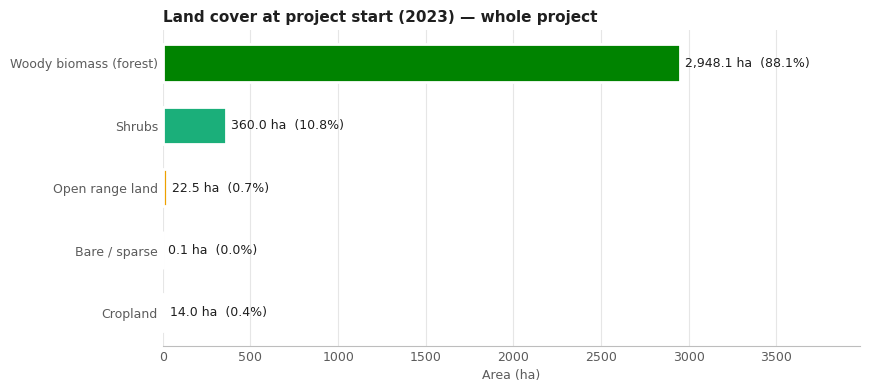

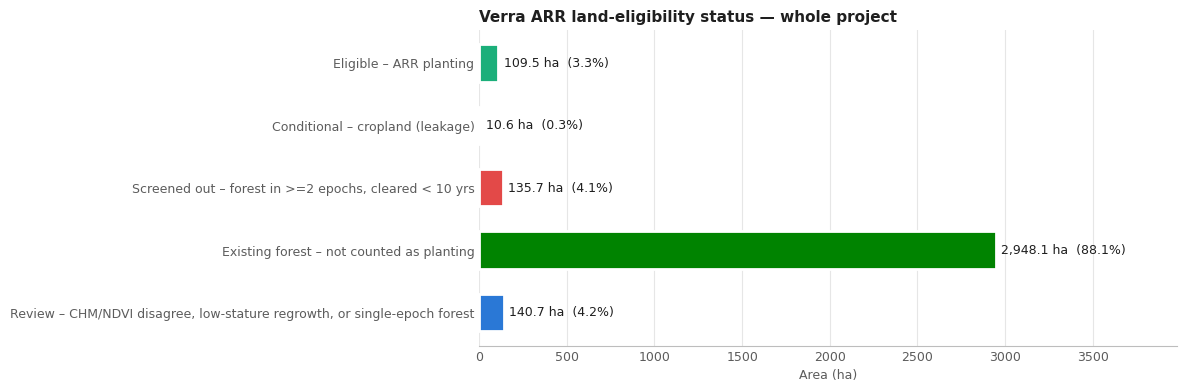

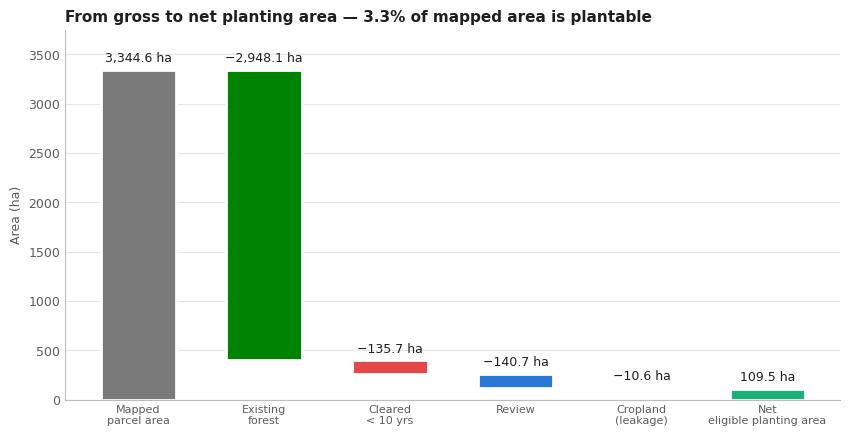

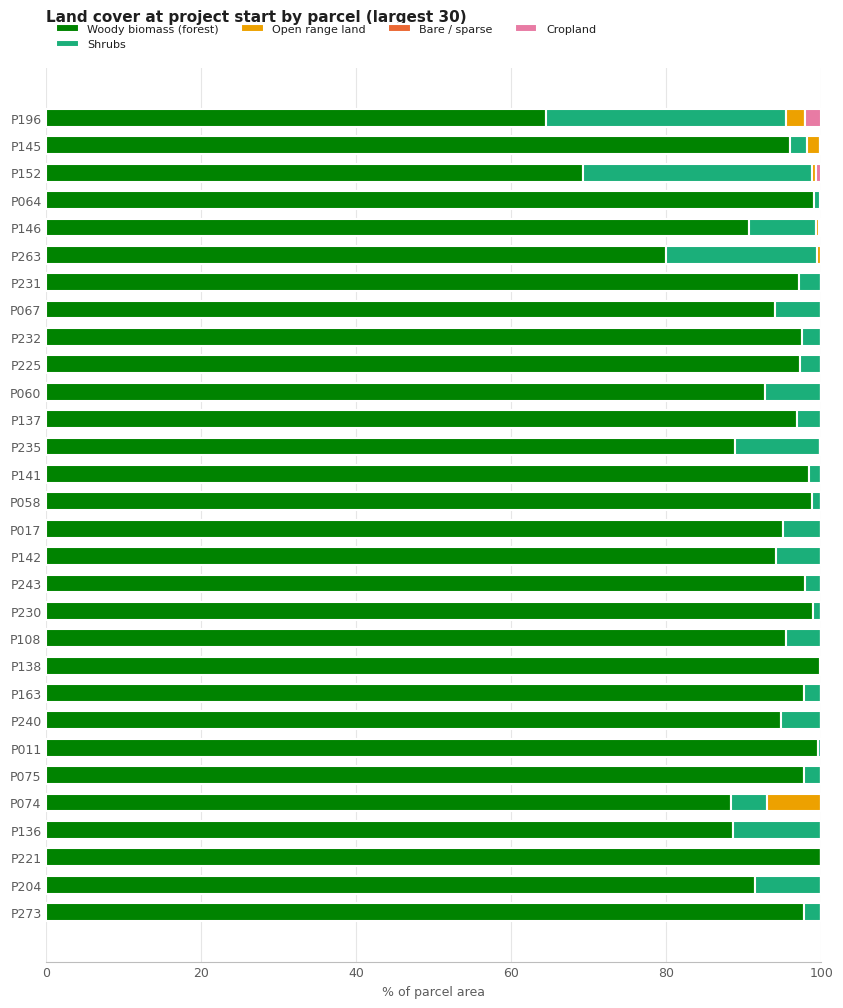

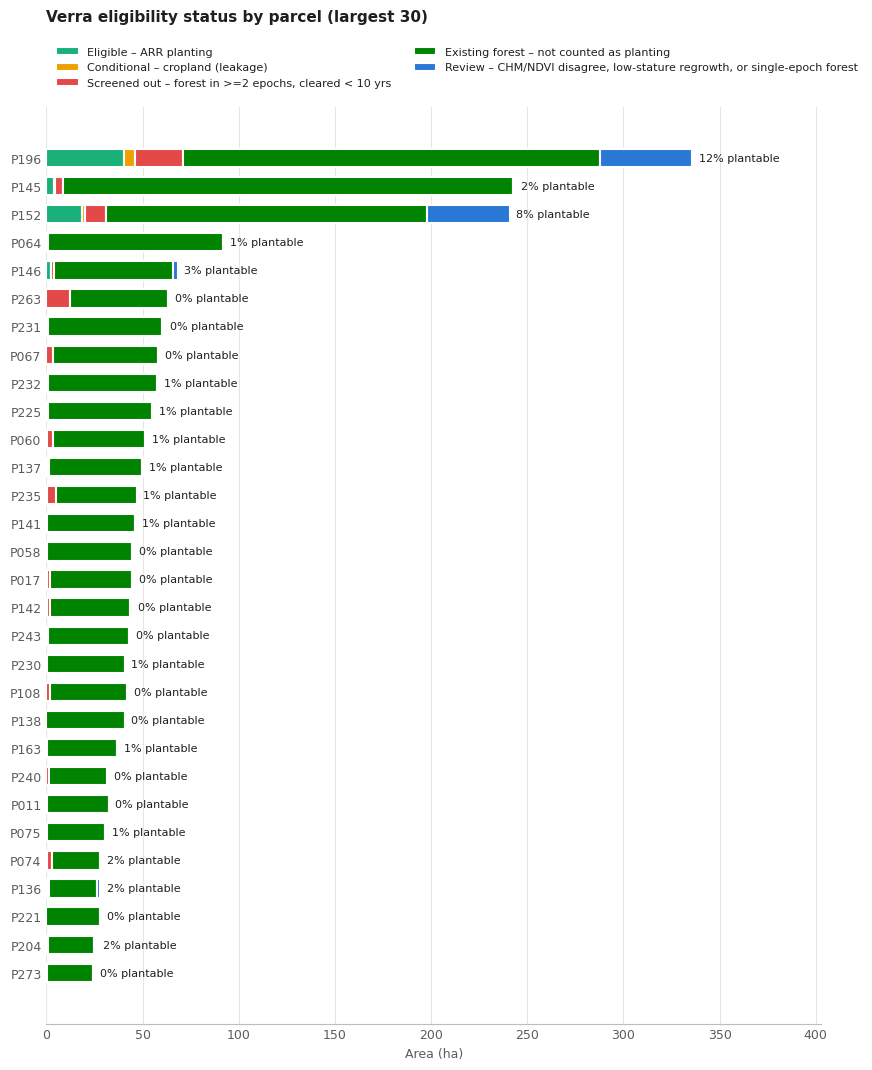

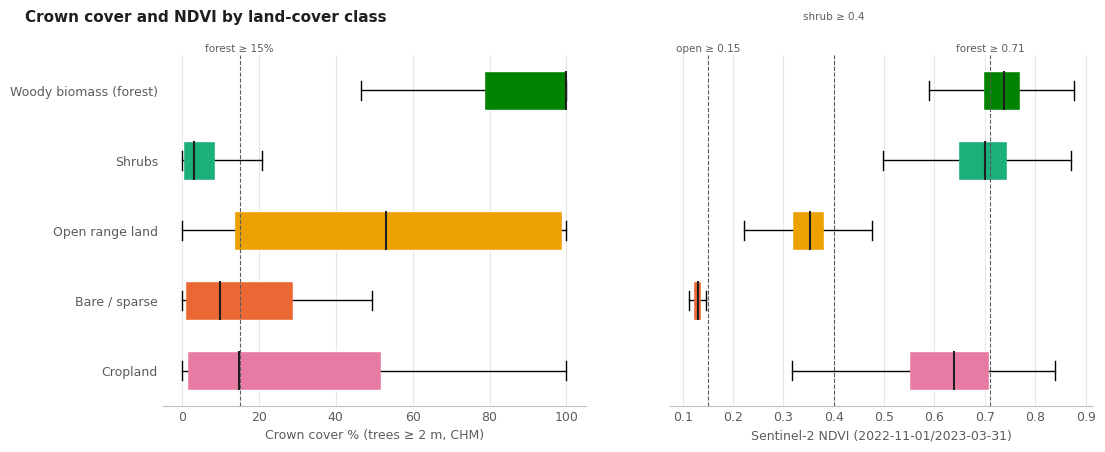

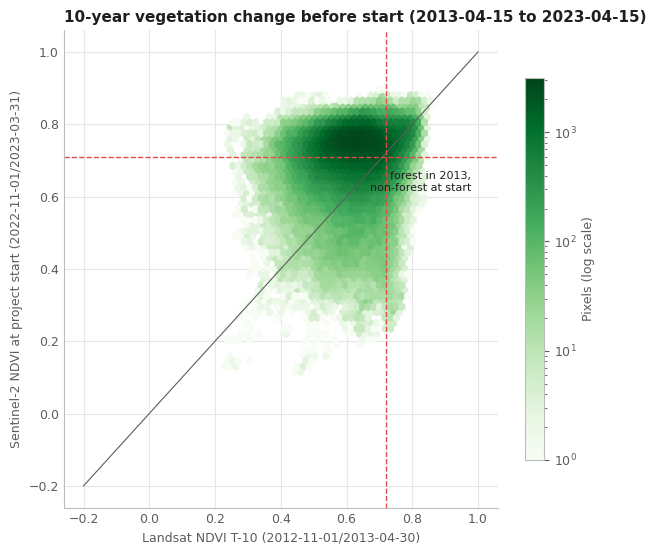

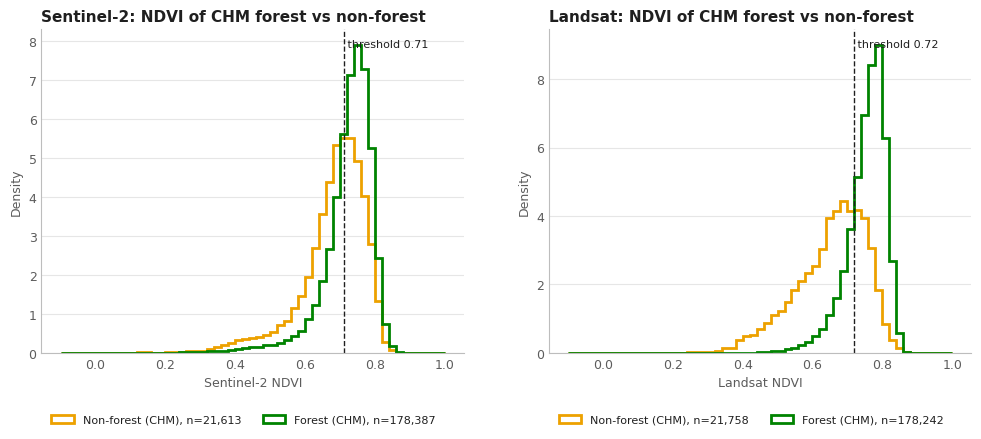

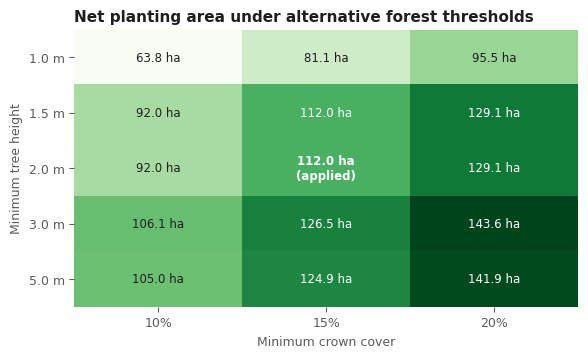

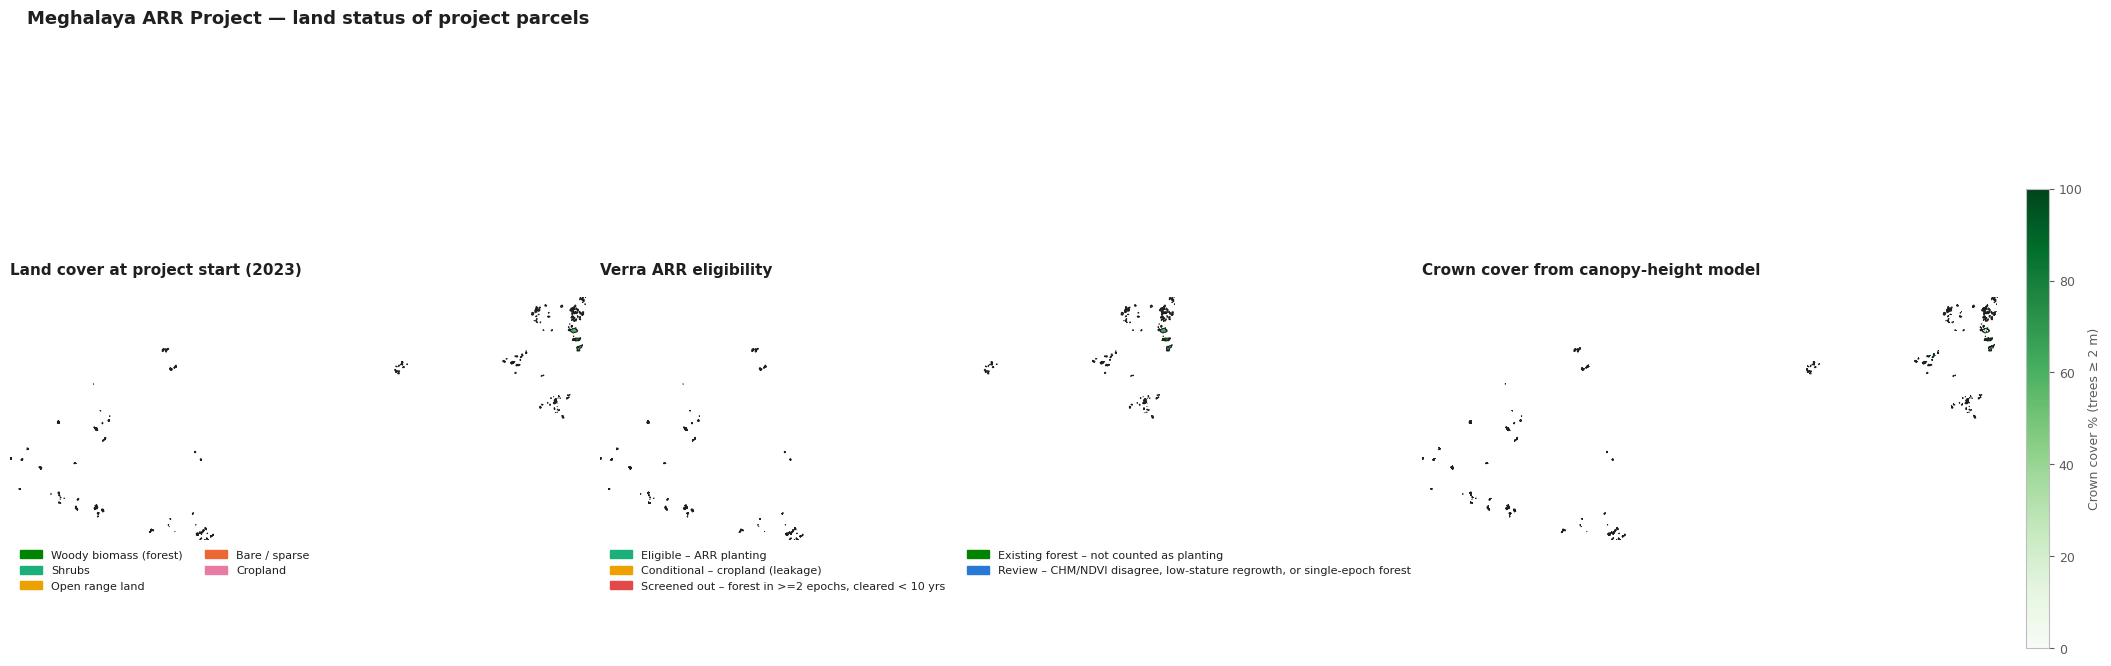

Charts: /content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Verra_ARR_Eligibility/charts | PDF report saved


In [ ]:
# ----------------------------- charts & PDF report -----------------------------
C = f"{OUT_DIR}/charts"
figs = []
def style(ax, axis="x"):
    for s in ["top", "right"] + (["left"] if axis == "x" else []):
        ax.spines[s].set_visible(False)
    if axis in ("x", "y", "both"):
        ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
def save(fig, name):
    fig.savefig(f"{C}/{name}.png", dpi=220, bbox_inches="tight")
    figs.append(fig)
    plt.show()
def top_parcels(table):
    t = table.drop(index="PROJECT TOTAL").sort_values("Parcel area (ha)", ascending=False)
    return t.head(TOP_N_PARCELS_IN_CHARTS).iloc[::-1]
def stacked_bars(ax, table, names, colors, pct):
    t = top_parcels(table)
    keys = [k for k in names if f"{names[k]} (ha)" in t.columns]
    vals = t[[f"{names[k]} (ha)" for k in keys]]
    if pct:
        vals = vals.div(vals.sum(axis=1).replace(0, np.nan), axis=0) * 100
    left = np.zeros(len(t))
    for k in keys:
        v = vals[f"{names[k]} (ha)"].fillna(0).values
        ax.barh(t.index, v, left=left, color=colors[k], height=0.65, edgecolor="white", linewidth=1.5, label=names[k])
        left += v
    return t, left
def hbar_total(series, colors, labels, title, name):
    s = series[series > 0]
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(s) + 1.6))
    y = np.arange(len(s))[::-1]
    ax.barh(y, s.values, color=[colors[i] for i in s.index], height=0.6, edgecolor="white", linewidth=2)
    ax.set_yticks(y, [labels[i] for i in s.index])
    for yi, v in zip(y, s.values):
        ax.text(v + s.max() * 0.01, yi, f"{v:,.1f} ha  ({100 * v / s.sum():.1f}%)", va="center")
    ax.set_xlim(0, s.max() * 1.35); ax.set_xlabel("Area (ha)")
    ax.set_title(title, loc="left"); style(ax); save(fig, name)

# 0. cover
fig = plt.figure(figsize=(8.27, 11.69))
fig.text(0.08, 0.93, PROJECT_NAME, fontsize=20, weight="bold")
fig.text(0.08, 0.905, "ARR land-eligibility & planting-area delineation", fontsize=11, color=INK2)
yy = 0.86
for k, v in kpi["Value"].items():
    fig.text(0.08, yy, k, fontsize=10, color=INK2)
    fig.text(0.56, yy, f"{v:,}" if isinstance(v, (int, float, np.floating)) else str(v), fontsize=10, weight="bold")
    yy -= 0.03
figs.append(fig)

# 0b. methods statement
cal_s2 = calib.set_index("Sensor").loc["Sentinel-2"]
cal_ls = calib.set_index("Sensor").loc["Landsat"]
def cal_txt(r):
    return (f"{r['Threshold used']} ({r['Source']}" + (f"; OA {r['Overall accuracy']:.2f}, kappa {r['Kappa']:.2f}"
            if "Overall accuracy" in r and pd.notna(r.get("Overall accuracy")) else "") + ")")
methods = (
    f"Methods statement\n\n"
    f"Land eligibility was assessed under {METHODOLOGY}, project start {PROJECT_START}. Forest was defined using "
    f"India's CDM A/R definition: minimum area {FOREST_MIN_HA} ha, minimum crown cover {FOREST_CROWN_COVER}% and "
    f"minimum tree height {FOREST_MIN_HEIGHT_M} m. Following the CDM/Marrakesh wording, the height criterion is potential height at maturity \n"
    f"in situ, so low-stature natural regrowth is treated as potential forest and is not counted as eligible land without field evidence.\n\n"
    f"Tree height and crown cover were derived from the Meta/WRI 1 m Global Canopy Height Map (Tolan et al. 2024). "
    f"Crown cover is the share of 1 m pixels with canopy ≥ {FOREST_MIN_HEIGHT_M} m within a moving {CC_WINDOW_M} m "
    f"window (≈0.05 ha), aggregated to a 10 m grid; contiguous forest patches smaller than {FOREST_MIN_HA} ha were "
    f"removed. Because the canopy-height imagery pre-dates the start date, canopy presence at start was confirmed with "
    f"the Sentinel-2 L2A dry-season median NDVI ({S2_DATES}); canopy with NDVI < {NDVI_CLEARED} was treated as removed.\n\n"
    f"NDVI forest thresholds were calibrated against canopy-height forest labels using Youden's J: Sentinel-2 "
    f"{cal_txt(cal_s2)}; Landsat {cal_txt(cal_ls)}. Calibrated Sentinel-2 NDVI classifies cells without canopy-height "
    f"data. Non-forest land was split into shrubs (NDVI ≥ {NDVI_SHRUB}), open range ({NDVI_OPEN}–{NDVI_SHRUB}) and "
    f"bare/sparse (< {NDVI_OPEN}); water, wetland, built-up and cropland come from ESA WorldCover 2021.\n\n"
    f"Compliance with the VCS requirement that no native ecosystem was cleared in the 10 years before the start date "
    f"({LOOKBACK}) was tested with Landsat 7/8/9 dry-season NDVI composites for {', '.join(HIST_EPOCHS)} plus the "
    f"canopy-height epoch. Land that was forest in at least {HIST_MIN_FOREST_EPOCHS} epochs but non-forest at start is screened out as cleared within the look-back "
    f"(VCS Standard v4.7 §3.19.29(2) provides an evidence route); a single-epoch hit goes to 'Review'. Land with fewer "
    f"than {MIN_HIST_EPOCHS} clear historical observations is 'Unverified', and land where canopy height and NDVI "
    f"disagree or that looks like low-stature regrowth (canopy ≥ {REGROWTH_HEIGHT_M} m at ≥ {FOREST_CROWN_COVER}% cover) is 'Review'; neither is counted as planting area.\n\n"
    f"Result: {net:,.1f} ha of {gross:,.1f} ha mapped ({100 * net / gross:.1f}%) is eligible for ARR planting. "
    f"Sensitivity to the definition thresholds (height {SENS_HEIGHTS} m × crown cover {SENS_CC}%) and the threshold "
    f"calibration statistics are reported in the statistics workbook. A stratified random sample of "
    f"{SAMPLES_PER_CLASS} points per mapped class is provided for accuracy assessment (Olofsson et al. 2014).")
fig = plt.figure(figsize=(8.27, 11.69))
import textwrap
fig.text(0.08, 0.95, "\n".join("\n".join(textwrap.wrap(p, 95)) if p else "" for p in methods.split("\n")),
         fontsize=9, va="top", linespacing=1.5)
figs.append(fig)

# 1-2. project totals
hbar_total(lc.groupby("class_id").area_ha.sum().reindex(list(CLASS_NAMES)).fillna(0), CLASS_COLORS, CLASS_NAMES,
           "Land cover at project start (2023) — whole project", "01_project_landcover_composition")
hbar_total(t_el_tot["Area (ha)"], ELIG_COLORS, ELIG_NAMES,
           "Verra ARR land-eligibility status — whole project", "02_project_eligibility_status")

# 3. waterfall
steps = [("Excluded", 4), ("Existing forest", 5), ("Cleared < 10 yrs", 3), ("Review", 7), ("Unverified", 6)]
if 2 not in PLANTING_ELIG:
    steps.append(("Cropland (leakage)", 2))
steps = [s for s in steps if s[1] not in PLANTING_ELIG]
fig, ax = plt.subplots(figsize=(10, 4.8))
labels, bottoms, heights, colors = ["Mapped parcel area"], [0], [gross], ["#7a7a7a"]
level = gross
for name, k in steps:
    v = t_el_tot.loc[k, "Area (ha)"]
    if v < 0.005:
        continue
    level -= v
    labels.append(name); bottoms.append(level); heights.append(v); colors.append(ELIG_COLORS[k])
labels.append("Net eligible planting area"); bottoms.append(0); heights.append(net); colors.append(ELIG_COLORS[1])
x = np.arange(len(labels))
ax.bar(x, heights, bottom=bottoms, color=colors, width=0.6, edgecolor="white", linewidth=2)
for i, (xi, b, h) in enumerate(zip(x, bottoms, heights)):
    ax.text(xi, b + h + gross * 0.015, f"{'' if i in (0, len(x) - 1) else '−'}{h:,.1f} ha", ha="center", va="bottom")
ax.set_xticks(x, [l.replace(" ", "\n", 1) if len(l) > 14 else l for l in labels], fontsize=8)
ax.set_ylabel("Area (ha)"); ax.set_ylim(0, gross * 1.12)
ax.set_title(f"From gross to net planting area — {100 * net / gross:.1f}% of mapped area is plantable", loc="left")
style(ax, "y"); save(fig, "03_gross_to_net_planting_waterfall")

# 4-5. per parcel
n = min(TOP_N_PARCELS_IN_CHARTS, len(t_lc) - 1)
sfx = f" (largest {n})" if len(t_lc) - 1 > n else ""
fig, ax = plt.subplots(figsize=(10, 0.32 * n + 2))
stacked_bars(ax, t_lc, CLASS_NAMES, CLASS_COLORS, pct=True)
ax.set_xlim(0, 100); ax.set_xlabel("% of parcel area")
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.01), frameon=False, fontsize=8)
ax.set_title("Land cover at project start by parcel" + sfx, loc="left", pad=34)
style(ax); save(fig, "04_parcel_landcover_composition")

fig, ax = plt.subplots(figsize=(10, 0.32 * n + 2.3))
t, totals = stacked_bars(ax, t_el, ELIG_NAMES, ELIG_COLORS, pct=False)
for yi, (tv, pc) in enumerate(zip(totals, t["Net planting %"])):
    ax.text(tv + totals.max() * 0.01, yi, f"{pc:.0f}% plantable", va="center", fontsize=8)
ax.set_xlim(0, totals.max() * 1.2); ax.set_xlabel("Area (ha)")
ax.legend(ncol=2, loc="lower left", bbox_to_anchor=(0, 1.01), frameon=False, fontsize=8)
ax.set_title("Verra eligibility status by parcel" + sfx, loc="left", pad=62)
style(ax); save(fig, "05_parcel_eligibility_status")

# 6. crown cover & NDVI distributions by class
present = [c for c in CLASS_NAMES if c in px.cls.unique()]
fig, axes = plt.subplots(1, 2, figsize=(12, 0.55 * len(present) + 1.8), sharey=True)
for ax, col, xlab, thr in [(axes[0], "cc", f"Crown cover % (trees ≥ {FOREST_MIN_HEIGHT_M} m, CHM)",
                            [(FOREST_CROWN_COVER, f"forest ≥ {FOREST_CROWN_COVER}%")]),
                           (axes[1], "ndvi", f"Sentinel-2 NDVI ({S2_DATES})",
                            [(NDVI_OPEN, f"open ≥ {NDVI_OPEN}"), (NDVI_SHRUB, f"shrub ≥ {NDVI_SHRUB}"),
                             (THR['Sentinel-2'], f"forest ≥ {THR['Sentinel-2']}")])]:
    data_ = [px.loc[px.cls == c, col].dropna() for c in present]
    data_ = [s.sample(min(100_000, len(s)), random_state=SEED).values if len(s) else np.array([np.nan]) for s in data_]
    bp = ax.boxplot(data_[::-1], vert=False, patch_artist=True, widths=0.55, showfliers=False,
                    medianprops=dict(color=INK, linewidth=1.5))
    for patch, c in zip(bp["boxes"], present[::-1]):
        patch.set_facecolor(CLASS_COLORS[c]); patch.set_edgecolor("white")
    for j, (v, lab) in enumerate(sorted(thr)):
        ax.axvline(v, color=INK2, linestyle="--", linewidth=0.8)
        ax.text(v, len(present) + 0.55 + 0.45 * (j % 2), lab, ha="center", fontsize=7.5, color=INK2)
    ax.set_xlabel(xlab); style(ax)
axes[0].set_yticks(range(1, len(present) + 1), [CLASS_NAMES[c] for c in present][::-1])
fig.suptitle("Crown cover and NDVI by land-cover class", x=0.01, ha="left", weight="bold", fontsize=11)
save(fig, "06_crown_cover_and_ndvi_by_class")

# 7. 10-year change
both = px[["ndvi_hist", "ndvi"]].dropna()
fig, ax = plt.subplots(figsize=(7, 6.2))
if len(both):
    hb = ax.hexbin(both.ndvi_hist, both.ndvi, gridsize=70, cmap="Greens", bins="log", mincnt=1, extent=(-0.2, 1, -0.2, 1))
    fig.colorbar(hb, ax=ax, label="Pixels (log scale)", shrink=0.8)
ax.plot([-0.2, 1], [-0.2, 1], color=INK2, linewidth=0.8)
ax.axvline(THR["Landsat"], color="#e34948", linestyle="--", linewidth=1)
ax.axhline(THR["Sentinel-2"], color="#e34948", linestyle="--", linewidth=1)
ax.text(0.98, THR["Sentinel-2"] - 0.04, "forest in 2013,\nnon-forest at start", ha="right", va="top", fontsize=8)
ax.set_xlabel(f"Landsat NDVI {first_epoch} ({HIST_EPOCHS[first_epoch]})")
ax.set_ylabel(f"Sentinel-2 NDVI at project start ({S2_DATES})")
ax.set_title(f"10-year vegetation change before start ({LOOKBACK})", loc="left")
style(ax, "both"); save(fig, "07_ten_year_ndvi_change")

# 8. calibration
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, name in zip(axes, ["Sentinel-2", "Landsat"]):
    df = calib_data.get(name, pd.DataFrame())
    if len(df):
        bins = np.linspace(-0.1, 1, 56)
        f_ = df.forest.astype(bool)
        ax.hist(df.ndvi[~f_], bins=bins, density=True, histtype="step", linewidth=2, color="#eda100",
                label=f"Non-forest (CHM), n={(~f_).sum():,}")
        ax.hist(df.ndvi[f_], bins=bins, density=True, histtype="step", linewidth=2, color="#008300",
                label=f"Forest (CHM), n={f_.sum():,}")
    ax.axvline(THR[name], color=INK, linestyle="--", linewidth=1)
    ax.text(THR[name], ax.get_ylim()[1] * 0.97, f" threshold {THR[name]}", va="top", fontsize=8)
    ax.set_xlabel(f"{name} NDVI"); ax.set_ylabel("Density"); ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.16), ncol=2)
    ax.set_title(f"{name}: NDVI of CHM forest vs non-forest", loc="left"); style(ax, "y")
save(fig, "08_ndvi_threshold_calibration")

# 9. sensitivity heatmap
pv = sens.pivot(index="Height (m)", columns="Crown cover (%)", values="Net planting (ha)")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(pv.values, cmap="Greens", aspect="auto")
ax.set_xticks(range(len(pv.columns)), [f"{c}%" for c in pv.columns])
ax.set_yticks(range(len(pv.index)), [f"{h} m" for h in pv.index])
for i, h in enumerate(pv.index):
    for j, c in enumerate(pv.columns):
        v = pv.values[i, j]
        dark = v > np.nanmean(pv.values)
        ax.text(j, i, f"{v:,.1f} ha" + ("\n(applied)" if (h, c) == (FOREST_MIN_HEIGHT_M, FOREST_CROWN_COVER) else ""),
                ha="center", va="center", fontsize=8.5, color="white" if dark else INK,
                weight="bold" if (h, c) == (FOREST_MIN_HEIGHT_M, FOREST_CROWN_COVER) else "normal")
ax.set_xlabel("Minimum crown cover"); ax.set_ylabel("Minimum tree height")
ax.set_title("Net planting area under alternative forest thresholds", loc="left")
for s in ax.spines.values():
    s.set_visible(False)
save(fig, "09_sensitivity_forest_definition")

# 10. maps
fig, axes = plt.subplots(1, 3, figsize=(21, 8), layout="constrained")
for ax, gdf, fld, names, cols_, title in [
        (axes[0], lc, "class_id", CLASS_NAMES, CLASS_COLORS, "Land cover at project start (2023)"),
        (axes[1], el, "elig_id", ELIG_NAMES, ELIG_COLORS, "Verra ARR eligibility")]:
    for k, col in cols_.items():
        sub = gdf[gdf[fld] == k]
        if len(sub):
            sub.plot(ax=ax, color=col, linewidth=0)
    parcels.boundary.plot(ax=ax, color=INK, linewidth=0.7)
    ax.legend(handles=[Patch(color=cols_[k], label=v) for k, v in names.items() if (gdf[fld] == k).any()],
              loc="upper left", bbox_to_anchor=(0, 0), ncol=2, fontsize=8, frameon=False)
    ax.set_title(title, loc="left"); ax.set_axis_off()
ax = axes[2]
for cc_arr, aff, shp in cc_tiles:
    ext = (aff.c, aff.c + aff.a * shp[1], aff.f + aff.e * shp[0], aff.f)
    im = ax.imshow(cc_arr, extent=ext, cmap="Greens", vmin=0, vmax=100, interpolation="nearest")
parcels.boundary.plot(ax=ax, color=INK, linewidth=0.7)
b = parcels.total_bounds
ax.set_xlim(b[0], b[2]); ax.set_ylim(b[1], b[3])
fig.colorbar(im, ax=ax, label=f"Crown cover % (trees ≥ {FOREST_MIN_HEIGHT_M} m)", shrink=0.6)
ax.set_title("Crown cover from canopy-height model", loc="left"); ax.set_axis_off()
for a in axes[:2]:
    a.set_xlim(b[0], b[2]); a.set_ylim(b[1], b[3])
fig.suptitle(f"{PROJECT_NAME} — land status of project parcels", x=0.01, ha="left", fontsize=13, weight="bold")
save(fig, "10_maps_landcover_eligibility_crowncover")

with PdfPages(f"{OUT_DIR}/Verra_ARR_Eligibility_Report.pdf") as pdf:
    for f in figs:
        pdf.savefig(f, bbox_inches="tight")
print("Charts:", C, "| PDF report saved")

In [ ]:
# ---------------- accuracy-assessment sample (Olofsson et al. 2014) ----------------
A = f"{OUT_DIR}/accuracy_assessment"
idx = np.concatenate([g.sample(min(SAMPLES_PER_CLASS, len(g)), random_state=SEED).index
                      for _, g in px[px.cls > 0].groupby("cls")])
smp = px.loc[idx].sample(frac=1, random_state=SEED).reset_index(drop=True)
smp.insert(0, "sample_id", [f"S{i+1:04d}" for i in range(len(smp))])
pts = gpd.GeoDataFrame(smp, geometry=gpd.points_from_xy(smp.x, smp.y), crs=CRS)
ll = pts.to_crs(4326)
pts["lon"], pts["lat"] = ll.geometry.x.round(6), ll.geometry.y.round(6)
pts["map_class"] = pts.cls.map(CLASS_NAMES)
pts["map_status"] = pts.elig.map(ELIG_NAMES)
for c in ["ref_class", "ref_trees_2m", "ref_crown_cover_pct", "ref_cleared_since_2013", "interpreter", "ref_date", "notes"]:
    pts[c] = ""
blind_cols = ["sample_id", PARCEL_ID_FIELD, "lon", "lat", "ref_class", "ref_trees_2m", "ref_crown_cover_pct",
              "ref_cleared_since_2013", "interpreter", "ref_date", "notes"]
pts[blind_cols].to_csv(f"{A}/samples_BLIND_for_interpreters.csv", index=False)
pts[blind_cols + ["geometry"]].to_file(f"{A}/samples_BLIND_UTM.shp")
try:
    pts[blind_cols + ["geometry"]].to_crs(4326).to_file(f"{A}/samples_BLIND.kml", driver="KML")
except Exception as e:
    print("KML skipped:", e)
pts[["sample_id", PARCEL_ID_FIELD, "cls", "map_class", "elig", "map_status", "method", "ndvi", "cc", "hmax",
     "lon", "lat"]].to_csv(f"{A}/samples_KEY_map_classes.csv", index=False)
pd.DataFrame({"code": list(CLASS_NAMES), "class": list(CLASS_NAMES.values())}).to_csv(f"{A}/class_legend.csv", index=False)
print(f"{len(pts)} sample points saved to {A}")
display(pts.groupby("map_class").size().rename("samples"))

# ---- eligibility-stratified sample: for an area-adjusted estimate of truly plantable land ----
ELIG_N = {1: 100, 7: 100}          # oversample the strata that matter most (eligible, Review)
e_idx = np.concatenate([g.sample(min(ELIG_N.get(k, SAMPLES_PER_CLASS), len(g)), random_state=SEED).index
                        for k, g in px[px.elig > 0].groupby("elig")])
se_ = px.loc[e_idx].sample(frac=1, random_state=SEED).reset_index(drop=True)
se_.insert(0, "sample_id", [f"E{i+1:04d}" for i in range(len(se_))])
pe = gpd.GeoDataFrame(se_, geometry=gpd.points_from_xy(se_.x, se_.y), crs=CRS)
lle = pe.to_crs(4326)
pe["lon"], pe["lat"] = lle.geometry.x.round(6), lle.geometry.y.round(6)
pe["map_status"] = pe.elig.map(ELIG_NAMES)
for c in ["ref_forest_at_start", "ref_crown_cover_pct", "ref_cleared_since_2013", "interpreter", "ref_date", "notes"]:
    pe[c] = ""
e_blind = ["sample_id", PARCEL_ID_FIELD, "lon", "lat", "ref_forest_at_start", "ref_crown_cover_pct",
           "ref_cleared_since_2013", "interpreter", "ref_date", "notes"]
pe[e_blind].to_csv(f"{A}/elig_samples_BLIND_for_interpreters.csv", index=False)   # fill ref_forest_at_start = Y/N, ref_cleared_since_2013 = Y/N
pe[["sample_id", PARCEL_ID_FIELD, "elig", "map_status", "lon", "lat"]].to_csv(f"{A}/elig_samples_KEY.csv", index=False)
print(f"{len(pe)} eligibility-stratified points saved:", pe.groupby("map_status").size().to_dict())


211 sample points saved to /content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Verra_ARR_Eligibility/accuracy_assessment


,samples
map_class,
Bare / sparse,11
Cropland,50
Open range land,50
Shrubs,50
Woody biomass (forest),50


350 eligibility-stratified points saved: {'Conditional – cropland (leakage)': 50, 'Eligible – ARR planting': 100, 'Existing forest – not counted as planting': 50, 'Review – CHM/NDVI disagree, low-stature regrowth, or single-epoch forest': 100, 'Screened out – forest in >=2 epochs, cleared < 10 yrs': 50}


In [ ]:
# ---------------- accuracy & area-adjusted estimates (run after interpretation) ----------------
REF_CSV = f"{A}/samples_BLIND_for_interpreters.csv"
ref = pd.read_csv(REF_CSV)
ref = ref[pd.to_numeric(ref.ref_class, errors="coerce").notna()]
if len(ref) == 0:
    print("No reference labels yet - fill ref_class (codes 1-7) in", REF_CSV, "and re-run this cell.")
else:
    key = pd.read_csv(f"{A}/samples_KEY_map_classes.csv")
    d_ = ref.merge(key[["sample_id", "cls"]], on="sample_id")
    d_["ref_class"] = d_.ref_class.astype(int)
    k = sorted(set(d_.cls) | set(d_.ref_class))
    cm = pd.crosstab(d_.cls, d_.ref_class).reindex(index=k, columns=k, fill_value=0)
    mapped = px[px.cls > 0].cls.value_counts().reindex(k, fill_value=0) * PIX_HA
    A_tot = mapped.sum(); W = mapped / A_tot
    n_i = cm.sum(axis=1).replace(0, np.nan)
    p = cm.div(n_i, axis=0).mul(W, axis=0).fillna(0)
    p_j = p.sum(axis=0)
    se = np.sqrt((W**2 * cm.div(n_i, axis=0) * (1 - cm.div(n_i, axis=0))).div(n_i - 1, axis=0).fillna(0).sum(axis=0))
    res = pd.DataFrame({
        "Class": [CLASS_NAMES.get(c, c) for c in k], "Mapped area (ha)": mapped.values,
        "User's accuracy %": (100 * np.diag(cm) / n_i).values,
        "Producer's accuracy %": (100 * np.diag(p) / p_j.replace(0, np.nan)).values,
        "Adjusted area (ha)": (p_j * A_tot).values, "95% CI ± (ha)": (1.96 * se * A_tot).values}, index=k)
    res["95% CI ± (%)"] = 100 * res["95% CI ± (ha)"] / res["Adjusted area (ha)"].replace(0, np.nan)
    oa = 100 * np.trace(p.values)
    print(f"Overall accuracy (area-weighted): {oa:.1f}%   |   n = {len(d_)} samples")
    with pd.ExcelWriter(f"{A}/Accuracy_Assessment_Results.xlsx", engine="openpyxl") as xw:
        cm.rename(index=CLASS_NAMES, columns=CLASS_NAMES).to_excel(xw, sheet_name="Confusion_Matrix")
        res.round(2).to_excel(xw, sheet_name="Accuracy_and_Area")
        pd.DataFrame({"Overall accuracy %": [oa], "Samples": [len(d_)]}).to_excel(xw, sheet_name="Overall", index=False)
    display(res.round(2))

No reference labels yet - fill ref_class (codes 1-7) in /content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Verra_ARR_Eligibility/accuracy_assessment/samples_BLIND_for_interpreters.csv and re-run this cell.


In [ ]:
# ---------------- area-adjusted estimate of TRULY plantable land (stratified by eligibility status) ----------------
REF_E = f"{A}/elig_samples_BLIND_for_interpreters.csv"
refe = pd.read_csv(REF_E, dtype=str)
yn = lambda s: s.str.strip().str.upper()
refe = refe[yn(refe.ref_forest_at_start).isin(["Y", "N"]) & yn(refe.ref_cleared_since_2013).isin(["Y", "N"])]
if len(refe) == 0:
    print("No reference labels yet - fill ref_forest_at_start and ref_cleared_since_2013 (Y/N) in", REF_E, "and re-run this cell.")
else:
    keye = pd.read_csv(f"{A}/elig_samples_KEY.csv")
    e = refe.merge(keye[["sample_id", "elig"]], on="sample_id")
    e["plantable"] = (yn(e.ref_forest_at_start) == "N") & (yn(e.ref_cleared_since_2013) == "N")
    area_h = (px[px.elig > 0].elig.value_counts() * PIX_HA).sort_index()
    A_tot = area_h.sum()
    rows = []
    for k, a in area_h.items():
        g = e[e.elig == k]
        n = len(g)
        p = g.plantable.mean() if n else np.nan
        rows.append({"elig_id": k, "Status": ELIG_NAMES[k], "Mapped area (ha)": a, "Labelled points": n,
                     "Share truly plantable": p,
                     "Truly plantable area (ha)": a * p if n else np.nan,
                     "var_term": (a / A_tot) ** 2 * p * (1 - p) / (n - 1) if n > 1 else np.nan})
    est = pd.DataFrame(rows).set_index("elig_id")
    miss = est.index[est["Labelled points"] < 2].tolist()
    if miss:
        print("WARNING: strata with < 2 labelled points (excluded from the SE):", miss)
    total_true = est["Truly plantable area (ha)"].sum()
    se_tot = A_tot * np.sqrt(est.var_term.sum())
    print(f"Truly plantable land (all strata): {total_true:,.1f} ha  ± {1.96 * se_tot:,.1f} ha (95% CI)  of {A_tot:,.1f} ha")
    pl = est.loc[[k for k in PLANTING_ELIG if k in est.index]]
    print(f"Mapped planting area: {pl['Mapped area (ha)'].sum():,.1f} ha | share of it truly plantable (user's accuracy): "
          f"{(pl['Truly plantable area (ha)'].sum() / pl['Mapped area (ha)'].sum()):.1%}")
    est.drop(columns="var_term").round(3).to_excel(f"{A}/Plantable_Area_Estimate.xlsx")
    display(est.drop(columns="var_term").round(3))


No reference labels yet - fill ref_forest_at_start and ref_cleared_since_2013 (Y/N) in /content/drive/MyDrive/Meghalaya_Data/Project_Parcels/Verra_ARR_Eligibility/accuracy_assessment/elig_samples_BLIND_for_interpreters.csv and re-run this cell.
